# Notebook 4 of 5 · Confidence-Aware Decision Mechanism (RQ2) and Stress Tests

**Project:** Confidence-Aware and Adversarially Robust Cyber Threat Analysis Using Explainable Machine Learning and Evidence-Grounded AI Agents · MSc Data Science Final Project · Spoorthi Hosakote Suresh

This notebook is one of five that together make up the project. It contains the original code **and the outputs of the reported run**, plus guidance added for reading, running and presenting it.

| # | Notebook | Parts of the original notebook | Answers | Needs as input |
|---|---|---|---|---|
| 1 | `01_data_foundation` | Part 1 (+ project overview) | O1 (threat model) | CIC-IDS2017 Kaggle dataset |
| 2 | `02_detectors` | Part 2 | baselines for all RQs | output of 1 |
| 3 | `03_adversarial_attacks` | Part 3 | **RQ1** | outputs of 1, 2 |
| 4 | `04_confidence_mechanism` | Parts 4 and 4b | **RQ2** | outputs of 1, 2, 3 |
| 5 | `05_agents_results_deployment` | Parts 5, 6, 7, 7b, 8 | **RQ3, RQ4**, final answers | outputs of 1, 2, 3, 4 |

**How this notebook is organised:** sections 1–5 below explain the notebook (what it does, how to run it, key concepts, methodology, key results). The original project code and outputs follow. A **viva guide** is at the end.

### Setup · presentation helpers
Writes the small flowchart helper used by every flowchart in this notebook. **Run this cell first** if you re-run any flowchart cell on its own.

In [1]:
# Presentation helpers (flowcharts, colours) are written once to a small module, so every Part can use them
import os, sys
from pathlib import Path
PRES_DIR = Path(os.environ.get("IDS_WORK_ROOT", "/kaggle/working")) / "presentation"
PRES_DIR.mkdir(parents=True, exist_ok=True)
(PRES_DIR / "present_lib.py").write_text(r'''"""Presentation helpers for the combined notebook: flowcharts and a shared colour palette."""
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch

FILL = {"data": "#DCE9F5", "model": "#E1F0DC", "attack": "#F8DEDB", "policy": "#FFEFD2",
        "agent": "#E9E1F4", "out": "#EFEFEF", "rq": "#FFFFFF", "accept": "#D7EFD7", "flag": "#FFE9B8", "escalate": "#F6C9C4"}
EDGE = {"data": "#3B6EA8", "model": "#4E9A47", "attack": "#C0453F", "policy": "#D9822B",
        "agent": "#7A5DB0", "out": "#7A7A7A", "rq": "#333333", "accept": "#3E8E41", "flag": "#C99100", "escalate": "#B3261E"}
SYSTEM_COLORS = {"A": "#9E9E9E", "B": "#4C72B0", "C": "#DD8452", "D": "#8172B3", "E": "#55A868"}
MODEL_COLORS = {"rf": "#4C72B0", "xgb": "#55A868", "mlp": "#C44E52"}


def _anchor(node, toward):
    x, y, w, h = node[:4]
    tx, ty = toward
    dx, dy = tx - x, ty - y
    if abs(dx) * h >= abs(dy) * w:           # leave through the left or right side
        return (x + (w / 2 + 0.6) * (1 if dx > 0 else -1), y)
    return (x, y + (h / 2 + 0.6) * (1 if dy > 0 else -1))


def flowchart(nodes, edges, size=(15, 6.5), title=None, fontsize=9.5, legend=None):
    """nodes: {key: (x, y, w, h, text, kind)} in a 0-100 x 0-50 canvas (centre coordinates).
    edges: [(from, to, label, rad)] - label and rad optional."""
    fig, ax = plt.subplots(figsize=size)
    ax.set_xlim(0, 100); ax.set_ylim(0, 50); ax.axis("off")
    for k, (x, y, w, h, text, kind) in nodes.items():
        ax.add_patch(FancyBboxPatch((x - w / 2, y - h / 2), w, h, boxstyle="round,pad=0.35,rounding_size=1.0",
                                    fc=FILL[kind], ec=EDGE[kind], lw=1.6, zorder=2))
        ax.text(x, y, text, ha="center", va="center", fontsize=fontsize, zorder=3, linespacing=1.25)
    for e in edges:
        a, b = e[0], e[1]
        label = e[2] if len(e) > 2 else ""
        rad = e[3] if len(e) > 3 else 0.0
        pa = _anchor(nodes[a], nodes[b][:2]); pb = _anchor(nodes[b], nodes[a][:2])
        ax.annotate("", xy=pb, xytext=pa, zorder=1,
                    arrowprops=dict(arrowstyle="-|>", color="#444444", lw=1.4, mutation_scale=14,
                                    connectionstyle=f"arc3,rad={rad}"))
        if label:
            mx, my = (pa[0] + pb[0]) / 2, (pa[1] + pb[1]) / 2
            ax.text(mx, my + 1.0 + 6 * abs(rad), label, ha="center", va="bottom", fontsize=fontsize - 1.5,
                    color="#333333", style="italic", zorder=4,
                    bbox=dict(boxstyle="round,pad=0.15", fc="white", ec="none", alpha=0.85))
    if legend:
        handles = [plt.Rectangle((0, 0), 1, 1, fc=FILL[k], ec=EDGE[k]) for k in legend]
        ax.legend(handles, list(legend.values()), loc="lower center", ncol=len(legend), frameon=False,
                  fontsize=fontsize - 1, bbox_to_anchor=(0.5, -0.04))
    if title:
        ax.set_title(title, fontsize=fontsize + 3, fontweight="bold", loc="left")
    plt.tight_layout()
    return fig, ax
''')
sys.path.insert(0, str(PRES_DIR))
print("presentation helpers ready:", PRES_DIR / "present_lib.py")

presentation helpers ready: /kaggle/working/presentation/present_lib.py


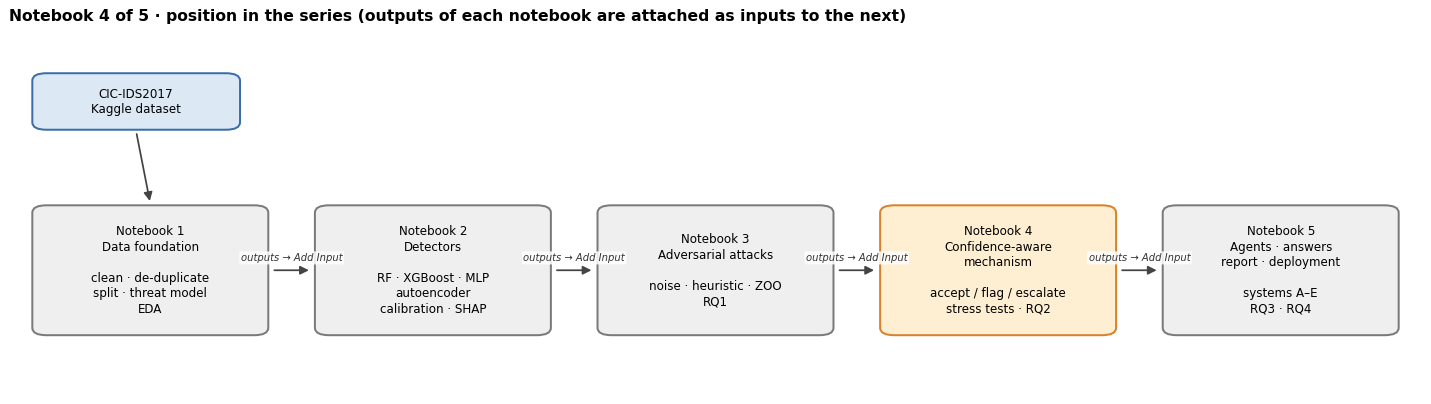

In [ ]:
import os, sys
from pathlib import Path
sys.path.insert(0, str(Path(os.environ.get("IDS_WORK_ROOT", "/kaggle/working")) / "presentation"))
import matplotlib.pyplot as plt
from present_lib import flowchart

# Where this notebook sits in the five-notebook series (highlighted box = this notebook)
nodes = {
    "data": (9, 40, 14, 7, "CIC-IDS2017\nKaggle dataset", "data"),
    "n1": (10, 17, 16, 17, 'Notebook 1\nData foundation\n\nclean · de-duplicate\nsplit · threat model\nEDA', "out"),
    "n2": (30, 17, 16, 17, 'Notebook 2\nDetectors\n\nRF · XGBoost · MLP\nautoencoder\ncalibration · SHAP', "out"),
    "n3": (50, 17, 16, 17, 'Notebook 3\nAdversarial attacks\n\nnoise · heuristic · ZOO\nRQ1', "out"),
    "n4": (70, 17, 16, 17, 'Notebook 4\nConfidence-aware\nmechanism\n\naccept / flag / escalate\nstress tests · RQ2', "policy"),
    "n5": (90, 17, 16, 17, 'Notebook 5\nAgents · answers\nreport · deployment\n\nsystems A–E\nRQ3 · RQ4', "out"),
}
edges = [("data", "n1")] + [(f"n{i}", f"n{i+1}", "outputs → Add Input") for i in range(1, 5)]
flowchart(nodes, edges, size=(16, 4.6), title="Notebook 4 of 5 · position in the series (outputs of each notebook are attached as inputs to the next)")
plt.show()

## 1 · What this notebook does

This notebook answers **RQ2**: *Can a confidence-aware decision mechanism identify cases where the classifier, anomaly detector and explanations disagree?* It builds the project's main contribution: a rule that combines three **trust indicators** and decides for every flow whether to **accept** it, **flag** it for more evidence, or **escalate** it to an analyst. Part 4b then stress-tests the mechanism.

| Item | Detail |
|---|---|
| Role in the project | **RQ2 / objective O2**; inputs to RQ3 and RQ4 |
| Input | Outputs of Notebooks 1, 2 and 3 |
| Output folders | `/kaggle/working/nb4_decision_policy/` (policy specification and thresholds, decisions on every flow version, evidence for the agents) and `/kaggle/working/nb4b_stress/` |
| Run time | estimated 30–60 minutes (the defence-aware attack and adversarial training in Part 4b are the slowest steps) |
| Hardware | **GPU T4** · Internet not needed |
| Report sections | 4.8, 5.3, 5.4 · Table 9 · Figures 5, 9, 10 |

## 2 · How to run

**General Kaggle steps (same for every notebook)**
1. On Kaggle, click **Create → New Notebook**, then **File → Import Notebook** and upload this `.ipynb` file.
2. In the right-hand panel, open **Session options** and set the **Accelerator** and **Internet** as listed below.
3. Click **+ Add Input** and attach the inputs listed below. Outputs of your earlier notebooks are found under **Your Work → Notebooks**: choose the notebook and attach its latest **output** version.
4. Click **Save Version → Save & Run All (Commit)**. Running as a saved version keeps the files in `/kaggle/working/` as this notebook's **output**, which the next notebook attaches.
5. When the run finishes, open the version and check the **Final checks** section (every row should show ✔).

**Why this works.** Every Part starts from a clean memory state and finds what it needs by file name, first in `/kaggle/working/` and then anywhere under `/kaggle/input/`. Attached outputs are therefore found automatically; no paths need to be edited.

**For the viva you do not need to re-run anything.** This file already contains every output of the reported run, so all tables and figures can be shown immediately.

**Settings for this notebook**

| Setting | Value |
|---|---|
| Accelerator | GPU T4 ×2 (or ×1) |
| Internet | Off |
| Inputs to attach | Outputs of **Notebooks 1, 2 and 3** |

**Settings you can change** (Sections 4.1 and 4b)

| Constant | Reported value | Meaning |
|---|---|---|
| `POLICY_MODEL` | xgb | detector inside the mechanism |
| `ANOMALY` | autoencoder | anomaly detector inside the mechanism |
| `FALSE_FLAG_BUDGETS`, `PRIMARY_BUDGET` | 0.05, 0.10 / 0.05 | max share of correct clean flows that may be flagged |
| `ALPHA_GRID`, `BETA_GRID` | 0–0.05 / 0.50–1.01 | candidate anomaly thresholds |
| `STAB_NOISE_SD`, `STAB_REPEATS` | 0.10, 4 | local-robustness perturbation |
| `N_BOOT` | 1,000 | bootstrap resamples |
| `DA_EPS`, `SEEDS`, `BUDGETS` (4b) | 0.2–1.0 / 1, 2, 3 / 1 %–20 % | stress-test settings |

## 3 · Key concepts and techniques

| Concept | In plain words | Why it is used here | Section |
|---|---|---|---|
| Trust indicator | A signal that a prediction may be wrong | The mechanism combines three | 4.5–4.6 |
| Calibrated confidence | The classifier's probability of its predicted class | Indicator 1 (alone it misses confident mistakes) | 4.6 |
| Classifier–anomaly agreement | Does the anomaly p-value agree with the classifier's verdict? | Indicator 2: an evasion must also look benign to a model of normal traffic | 4.6 |
| Explanation robustness | **Prototype similarity**: cosine similarity between a flow's SHAP vector and the typical SHAP vector of its predicted family | Indicator 3, the **novel** one; needs no clean copy of the flow | 4.5 |
| Local robustness | Agreement of SHAP rankings under small random perturbations | Alternative indicator (AUROC 0.794 < 0.867) | 4.5b |
| Four checks | Low confidence; possible evasion; unsupported alarm; unstable explanation | Transparent rule an analyst can read | 4.6 |
| Accept / flag / escalate | 0 checks failed / 1 failed / ≥ 2 or possible evasion | Route only suspicious flows to costly analysis | 4.6 |
| False-flag budget | At most 5 % of correctly classified clean flows may be flagged | Controls analyst workload | 4.6 |
| Unseen-attack tuning | ZOO flows crafted against the policy detector are excluded from tuning | The adaptive attack stays unseen until the test | 4.6 |
| Learned combiner | Logistic regression on the same indicators | Less transparent alternative | 4.6 |
| Ablation | Every subset of the three indicators | Does each indicator earn its place? | 4.8 |
| Risk–coverage / AURC | Error rate of accepted flows as coverage grows | Standard view of selective prediction | 4.9 |
| Flow-level paired bootstrap | Resample whole flows (all their attacked versions together) | Honest confidence intervals for differences | 4.10 |
| Defence-aware attack | Attacker who knows the thresholds and attacks all four checks | Strongest objection to the mechanism | 4b.2 |
| Adversarial training | Retrain on adversarial flows | Standard defence, as a comparison | 4b.3 |

## 4 · Methodology at a glance

| Step | What happens | Why | Section |
|---|---|---|---|
| Versions table | Every clean and attacked version of every flow in one table | Same inputs for every indicator | 4.3–4.4 |
| Explanation robustness | Local robustness and prototype similarity; pick the better | Deployable third indicator | 4.5–4.5b |
| Policy | Four checks; thresholds tuned on thr-lite (adaptive ZOO excluded) at a 5 % budget | Transparent rule | 4.6 |
| Evaluate | test-lite, reported once | RQ2 | 4.7 |
| Ablation | All indicator subsets + learned combiner | Contribution of each indicator | 4.8 |
| Risk–coverage | AURC per indicator | Selective-prediction view | 4.9 |
| Bootstrap | Flow-level paired differences | Which differences are real | 4.10 |
| Unseen families | Heartbleed and Infiltration | Never-seen attacks | 4.11 |
| Individual detectors | Accepted macro-F1 vs detectors without rejection | Input to RQ3 | 4.12 |
| Cost | Latency per flow | Input to RQ4 | 4.13 |
| Evidence | Evidence items for the agents | Input to Notebook 5 | 4.14 |
| Stress tests | Defence-aware attack, adversarial training, seeds, workload sweep | Limits of the claims | 4b |

## 5 · Key results to remember

| Result | Value |
|---|---|
| Tuned thresholds | τ_conf = 0.922 · α = 0.05 · β = 0.95 · τ_stab = −0.249 |
| AUROC for recognising wrong predictions | confidence 0.738 · anomaly agreement 0.943 · local robustness 0.794 · **prototype similarity 0.867** |
| Full rule at a 5 % budget | **96.0 %** of errors caught under attack (confidence alone 41.4 %); **91.4 %** of unseen adaptive evasions caught; 5.0 % clean false flags |
| Coverage | 90.9 % of clean flows and 46.1 % of attacked flows accepted automatically |
| Accepted macro-F1 under attack | **0.850** vs 0.602 for the detector without rejection |
| Bootstrap differences | full rule − confidence only **+0.546 [+0.533, +0.558]**; − anomaly only +0.098 [+0.091, +0.106] |
| Never-seen families | 100 % of Heartbleed and 92 % of Infiltration not accepted |
| Cost | about **8.7 ms** per flow (8.0 ms is the classifier) |
| Defence-aware attacker (4b.2) | attacker wins 6.3 % → 31.4 %; evasions caught 92.0 % → 55.6 % |
| Adversarial training (4b.3) | macro-F1 under the adaptive attack 0.253 → 0.960, clean −0.003 |
| Seeds (4b.4) | std ≤ 0.0005 clean, ≤ 0.013 under attack |
| Workload sweep (4b.5) | 1 % budget: 90.0 % of errors caught, 37.8 % of attacked flows sent onward |

---
# Original project code and outputs
Everything below is the project code exactly as in the reported run, with its outputs. Grey **Findings** boxes are generated by the code above them.

<a id="part4"></a>
# Part 4 · Confidence-Aware Decision Mechanism (RQ2)

| | |
|---|---|
| **Goal** | Combine calibrated confidence, anomaly evidence and explanation robustness into an accept / flag / escalate mechanism and test it on clean and attacked traffic. |
| **Answers** | **RQ2 / O2** (and inputs to RQ3, RQ4) |
| **Inputs** | Parts 1–3 outputs |
| **Outputs used later** | decisions and evidence for every test flow, policy specification, evaluation tables |
| **Run time** | ≈ 15 min (GPU) |

#### Research question answered here
> **RQ2:** Can a decision mechanism that combines calibrated classifier confidence, anomaly evidence and explanation robustness identify the predictions that should not be trusted, on clean and on adversarially perturbed traffic?
>
> **O2:** Design a confidence-aware mechanism that fuses the three trust indicators, detects disagreement between classifier, anomaly detector and explanation, and decides to **accept**, **flag** or **escalate** each flow.

#### The three trust indicators (all computable for a new flow, without its clean original)
*Terminology.* The mechanism combines three **trust indicators** (below), measured for every flow. A **check** fails when an indicator crosses its **threshold** (τ_c, α, β, τ_s); the settings of the models are **hyper-parameters**.

| Indicator | Meaning | Source |
|---|---|---|
| **Calibrated confidence** | probability of the predicted class after Dirichlet calibration | Part 2 calibrator, recomputed here |
| **Anomaly p-value** | conformal p-value of the autoencoder against benign calibration traffic | Part 3 (`attack_predictions.parquet`) |
| **Explanation robustness** | how stable and how typical the flow's SHAP explanation is (Section 4.5) | computed here with exact TreeSHAP |

**Why explanation robustness is recomputed.** Part 3 measured SHAP stability by comparing an attacked flow's explanation with the explanation of its *clean original*. That is valid evidence for RQ1, but a deployed system never sees the clean original, so it cannot drive a decision. Two deployable measures are therefore computed for every flow:
* **local robustness**: the rank correlation between the flow's SHAP ranking and the rankings of slightly perturbed copies of the same flow (an explanation that changes under tiny input noise is not trustworthy; Alvarez-Melis and Jaakkola, 2018);
* **prototype similarity**: the cosine similarity between the flow's SHAP vector and the average SHAP vector of training flows of the predicted family (the class prototypes saved in Part 2).

The measure that better separates correct from wrong predictions on `thr-lite` is used by the policy; both are reported.

#### Protocol
| Data | Used for |
|---|---|
| `thr-lite`: clean, noise, heuristic and **transferred** ZOO flows (crafted on RF or MLP) | choosing the stability measure, tuning thresholds, fitting the learned combiner |
| `thr-lite`: ZOO flows crafted on the policy detector itself | **never used**: the adaptive attack on the deployed model stays unseen until the test |
| `test-lite` (all versions) | reporting only |
| unseen families (Heartbleed, Infiltration) | generalisation check: are flows of never-seen families sent to an analyst? |

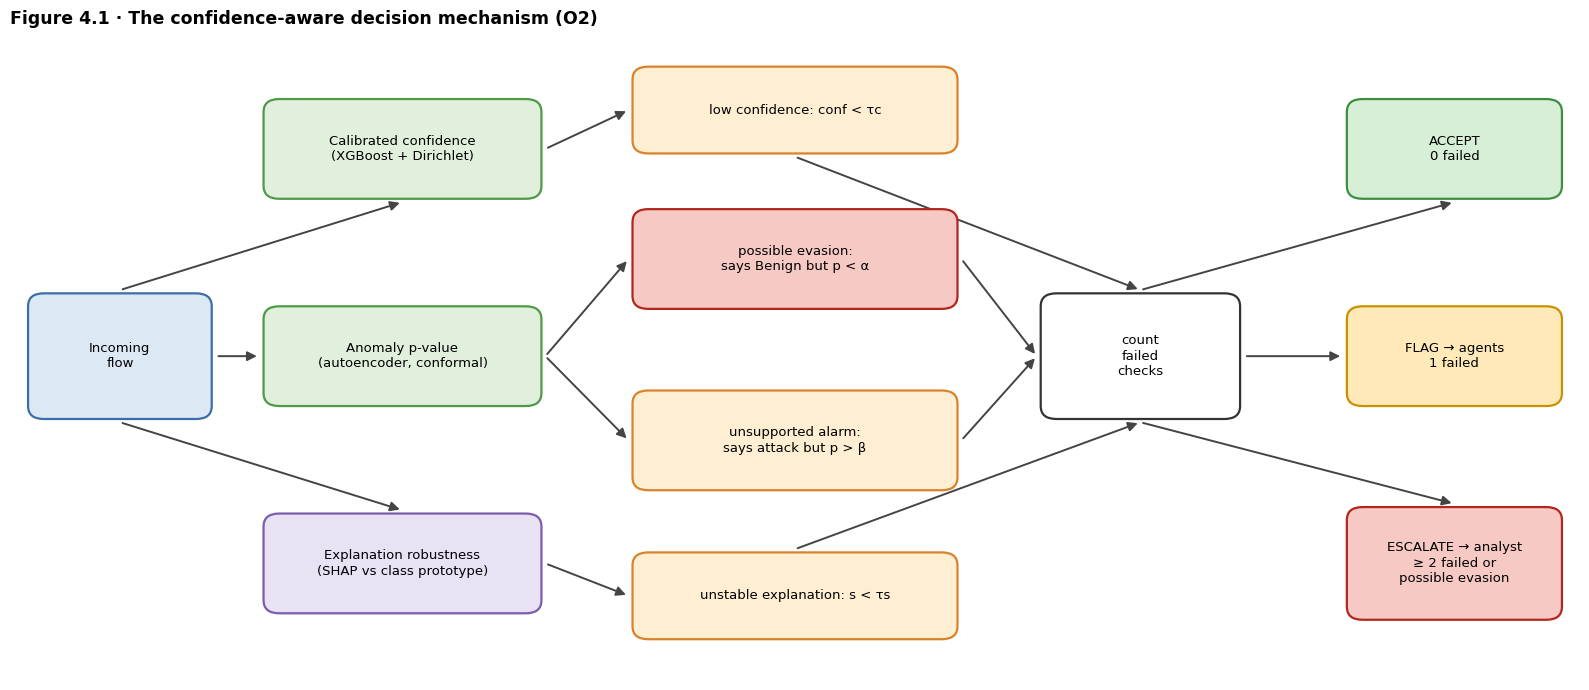

In [73]:
import os, sys
from pathlib import Path
sys.path.insert(0, str(Path(os.environ.get("IDS_WORK_ROOT", "/kaggle/working")) / "presentation"))
import matplotlib.pyplot as plt
from present_lib import flowchart

nodes = {
    "flow": (7, 25, 11, 9, "Incoming\nflow", "data"),
    "s1": (25, 41, 17, 7, "Calibrated confidence\n(XGBoost + Dirichlet)", "model"),
    "s2": (25, 25, 17, 7, "Anomaly p-value\n(autoencoder, conformal)", "model"),
    "s3": (25, 9, 17, 7, "Explanation robustness\n(SHAP vs class prototype)", "agent"),
    "c1": (50, 44, 20, 6, "low confidence: conf < τc", "policy"),
    "c2": (50, 32.5, 20, 7, "possible evasion:\nsays Benign but p < α", "escalate"),
    "c3": (50, 18.5, 20, 7, "unsupported alarm:\nsays attack but p > β", "policy"),
    "c4": (50, 6.5, 20, 6, "unstable explanation: s < τs", "policy"),
    "n": (72, 25, 12, 9, "count\nfailed\nchecks", "rq"),
    "acc": (92, 41, 13, 7, "ACCEPT\n0 failed", "accept"),
    "flg": (92, 25, 13, 7, "FLAG → agents\n1 failed", "flag"),
    "esc": (92, 9, 13, 8, "ESCALATE → analyst\n≥ 2 failed or\npossible evasion", "escalate"),
}
edges = [("flow", "s1"), ("flow", "s2"), ("flow", "s3"), ("s1", "c1"), ("s2", "c2"), ("s2", "c3"), ("s3", "c4"),
         ("c1", "n"), ("c2", "n"), ("c3", "n"), ("c4", "n"), ("n", "acc"), ("n", "flg"), ("n", "esc")]
flowchart(nodes, edges, size=(16, 7), title="Figure 4.1 · The confidence-aware decision mechanism (O2)")
plt.show()

## 4.1 · Setup and decisions

In [74]:
# Fresh start: this Part reloads everything it needs from the files saved by earlier Parts,
# so memory from the previous Part (e.g. the 2.8 M-row table of Part 1) is released first.
%reset -f
import gc; gc.collect()

0

In [75]:
import os, sys, json, time, platform, warnings, gc
from pathlib import Path
from datetime import datetime, timezone
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import joblib, sklearn, xgboost as xgb, shap
from scipy.stats import rankdata, spearmanr
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import roc_auc_score
from sklearn.neighbors import NearestNeighbors
from IPython.display import display, Markdown
warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 40); pd.set_option("display.width", 220)

INPUT_ROOT = Path(os.environ.get("IDS_INPUT_ROOT", "/kaggle/input"))
WORK_ROOT  = Path(os.environ.get("IDS_WORK_ROOT", "/kaggle/working"))
OUT_DIR = WORK_ROOT / "nb4_decision_policy"; FIG_DIR = OUT_DIR / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)
NOTEBOOK_ID = "nb4_decision_policy_v2"
SEED = 42

# ---------------- Decisions ----------------
POLICY_MODEL   = "xgb"            # best clean model (Part 2); tree-based, so exact TreeSHAP costs < 1 ms per flow
OTHER_MODELS   = ["rf", "mlp"]    # second opinions, passed to the agents in Part 5
ANOMALY        = "autoencoder"    # primary anomaly detector chosen in Part 2
STAB_NOISE_SD  = 0.10             # local robustness: Gaussian noise (standardised units) on continuous inputs
STAB_REPEATS   = 4                # perturbed copies per flow
FALSE_FLAG_BUDGETS = [0.05, 0.10] # max share of correctly classified CLEAN thr-lite flows that may be flagged
PRIMARY_BUDGET = 0.05             # budget of the policy handed to Part 5
CONF_QUANTILES = np.linspace(0, 0.30, 16)   # candidate confidence thresholds (quantiles of tuning confidence)
STAB_QUANTILES = np.linspace(0, 0.30, 16)   # candidate stability thresholds
ALPHA_GRID = [0.0, 0.001, 0.005, 0.01, 0.02, 0.05]   # benign verdict but anomaly p < alpha -> possible evasion (0 = off)
BETA_GRID  = [0.50, 0.80, 0.95, 1.01]               # attack verdict but anomaly p > beta -> unsupported alarm (1.01 = off)
ESCALATE_SHARE = 0.2              # learned combiner: escalation threshold at (budget × this share) of clean flows
KNN_K  = 5                        # similar training cases passed to the agents
N_BOOT = 1000

ENV = {"notebook_id": NOTEBOOK_ID, "run_started_utc": datetime.now(timezone.utc).isoformat(timespec="seconds"),
       "python": platform.python_version(), "numpy": np.__version__, "pandas": pd.__version__,
       "scikit-learn": sklearn.__version__, "xgboost": xgb.__version__, "shap": shap.__version__}
display(pd.DataFrame(ENV.items(), columns=["item", "value"]))

def findings(rows, meaning=""):
    text = "> #### Findings\n> | Check | Result |\n> |---|---|\n" + "".join(f"> | {a} | {b} |\n" for a, b in rows)
    if meaning: text += f">\n> **Meaning:** {meaning}\n"
    display(Markdown(text))

def savefig(name):
    plt.tight_layout(); plt.savefig(FIG_DIR / name, dpi=200, bbox_inches="tight"); plt.show()

def to_builtin(o):
    if isinstance(o, np.integer): return int(o)
    if isinstance(o, (np.floating, float)): return float(o) if np.isfinite(o) else None
    if isinstance(o, np.bool_): return bool(o)
    if isinstance(o, np.ndarray): return o.tolist()
    if isinstance(o, Path): return str(o)
    raise TypeError(type(o))

def macro_f1(y, p, K):
    """Macro-F1 over the classes present in y (same definition as Parts 2 and 3)."""
    y = np.asarray(y, dtype=int); p = np.asarray(p, dtype=int)
    if len(y) == 0: return np.nan
    cm = np.bincount(y * K + p, minlength=K * K).reshape(K, K)
    tp = np.diag(cm); prec = tp / np.maximum(cm.sum(0), 1); rec = tp / np.maximum(cm.sum(1), 1)
    f1 = np.where(prec + rec > 0, 2 * prec * rec / np.maximum(prec + rec, 1e-12), 0)
    return float(f1[cm.sum(1) > 0].mean())

,item,value
0,notebook_id,nb4_decision_policy_v2
1,run_started_utc,2026-10-24T18:03:55+00:00
2,python,3.13.15
3,numpy,2.1.3
4,pandas,2.3.3
5,scikit-learn,1.6.1
6,xgboost,3.4.1
7,shap,0.52.0


## 4.2 · Load the outputs of Parts 1–3

In [76]:
def find_dir(marker, local):
    hits = sorted((WORK_ROOT / local).glob(marker)) + sorted(INPUT_ROOT.rglob(marker))  # this run first, then attached outputs
    assert hits, f"{marker} not found: attach the output of the earlier part with 'Add Input'."
    if len({h.parent for h in hits}) > 1:
        print(f"note: several copies of {marker}; using {hits[0].parent}")
    return hits[0].parent

NB1 = find_dir("threat_model.json", "nb1_data_foundation")
NB2 = find_dir("detectors_config.json", "nb2_detectors")
NB3 = find_dir("attack_config.json", "nb3_attacks")
sys.path.insert(0, str(NB1)); sys.path.insert(0, str(NB2))
import preprocess_lib as pl, models_lib as ml          # models_lib defines the calibrator classes
CFG = json.load(open(NB2 / "detectors_config.json")); PARAMS = json.load(open(NB1 / "preprocessing_params.json"))
CLASSES, COLS = CFG["classes"], CFG["model_cols"]; K = len(CLASSES); BENIGN_ID = CLASSES.index("Benign")
assert POLICY_MODEL in CFG["classifiers"] and ANOMALY in CFG["anomaly_detectors"]
try:
    import torch
    DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
except ImportError:
    DEVICE = "cpu"

MODEL = xgb.XGBClassifier(); MODEL.load_model(NB2 / "models" / f"{POLICY_MODEL}.json")
try: MODEL.set_params(device=DEVICE)
except Exception: pass
CALIB = joblib.load(NB2 / "models" / f"calibrator_{POLICY_MODEL}.joblib")
def calibrated_proba(X):
    P = CALIB.predict_proba(np.log(np.clip(MODEL.predict_proba(X), 1e-12, 1))); return P / P.sum(1, keepdims=True)

PRED     = pd.read_parquet(NB3 / "attack_predictions.parquet")
ADVF     = pd.read_parquet(NB3 / "adversarial_flows.parquet")
STAB_REF = pd.read_parquet(NB3 / "shap_stability_per_flow.parquet")
CLEANP   = pd.read_parquet(NB2 / "predictions_clean.parquet")
SH       = np.load(NB2 / "shap_clean.npz", allow_pickle=True)
COST2    = pd.read_csv(NB2 / "cost_profile.csv", index_col=0)
NB2_EVAL = pd.read_csv(NB2 / "clean_eval.csv")
assert list(SH["columns"]) == COLS, "Part 2 SHAP columns differ from the model columns"
findings([("Part 1 / 2 / 3 outputs", f"{NB1.name} / {NB2.name} / {NB3.name}"),
          ("Classes", ", ".join(CLASSES)), ("Model input columns", f"{len(COLS)}"),
          ("Prediction rows from Part 3", f"{len(PRED):,}"), ("Adversarial flows from Part 3", f"{len(ADVF):,}"),
          ("Policy detector / anomaly detector", f"{POLICY_MODEL} / {ANOMALY}"), ("Device", DEVICE)])

> #### Findings
> | Check | Result |
> |---|---|
> | Part 1 / 2 / 3 outputs | nb1_data_foundation / nb2_detectors / nb3_attacks |
> | Classes | Benign, Bot, BruteForce, DDoS, DoS, PortScan, WebAttack |
> | Model input columns | 61 |
> | Prediction rows from Part 3 | 99,398 |
> | Adversarial flows from Part 3 | 80,575 |
> | Policy detector / anomaly detector | xgb / autoencoder |
> | Device | cuda |


## 4.3 · One table of flow versions
Every row is one *version* of a flow: its clean version, or its version under one attack, budget ε and target model. Benign flows are never perturbed, so in an attacked version they are identical to the clean one, exactly as a deployed system would see them. The evaluation groups are:

| Group | Meaning |
|---|---|
| `clean` | no attack |
| `noise`, `heuristic` | model-agnostic perturbations (Part 3) |
| `zoo_transfer` | ZOO crafted against RF or MLP, applied to the policy detector (black-box transfer) |
| `zoo_direct` | ZOO crafted against the policy detector itself: the adaptive worst case, **held out of all tuning** |
| `unseen` | Heartbleed and Infiltration flows, never seen in training |

In [77]:
P = PRED.copy()
P["set"] = P["set"].astype(str).map({"test_lite": "test", "thr_lite": "thr"})
assert P["set"].notna().all(), "unexpected set names in attack_predictions.parquet"
P["attack"] = P["attack"].astype(str); P["target"] = P["target"].astype(str)
P["eps"] = P["eps"].astype(float).round(6)
P["variant"] = np.where(P["attack"] == "clean", "clean", "attacked")
P["group"] = np.select([P.attack.eq("clean"), P.attack.eq("noise"), P.attack.eq("heuristic"), P.target.eq(POLICY_MODEL)],
                       ["clean", "noise", "heuristic", "zoo_direct"], "zoo_transfer")
P["y"] = P["label_id"].astype(int)
P["family"] = np.array(CLASSES)[P["y"].to_numpy()]

U = CLEANP[CLEANP["split"].astype(str) == "unseen"].copy()
U["set"], U["attack"], U["target"], U["eps"] = "unseen", "clean", "none", 0.0
U["variant"], U["group"], U["y"], U["family"] = "clean", "unseen", -1, U["Label"].astype(str)

PCOLS = [f"{m}_p_{c}" for m in [POLICY_MODEL] + OTHER_MODELS for c in CLASSES]
KEEP = ["set", "attack", "target", "eps", "row_id", "variant", "group", "y", "family"] + PCOLS + [f"{ANOMALY}_pvalue"]
F = pd.concat([P[KEEP], U[KEEP]], ignore_index=True)
for m in [POLICY_MODEL] + OTHER_MODELS:
    Pm = F[[f"{m}_p_{c}" for c in CLASSES]].to_numpy("float64")
    F[f"pred_{m}"] = Pm.argmax(1).astype(int); F[f"conf_{m}"] = Pm.max(1)
F["pred"], F["conf"] = F[f"pred_{POLICY_MODEL}"], F[f"conf_{POLICY_MODEL}"]
F["anomaly_p"] = F[f"{ANOMALY}_pvalue"].astype(float)
known = F["y"] >= 0
F["is_error"] = known & (F["pred"] != F["y"])
F["is_evasion"] = known & (F["y"] != BENIGN_ID) & (F["pred"] == BENIGN_ID)
F["is_attack_flow"] = F["y"] != BENIGN_ID
F["version_id"] = np.arange(len(F))
GROUP_TABLE = (F.groupby(["set", "group"])
                 .agg(versions=("y", "size"), error_rate=("is_error", "mean"), evasions=("is_evasion", "sum"))
                 .round(4))
display(GROUP_TABLE)
findings([("Flow versions (thr / test / unseen)", " / ".join(f"{int((F.set == s).sum()):,}" for s in ["thr", "test", "unseen"])),
          ("Policy-detector error rate: clean test / zoo_direct test",
           f"{F[(F.set == 'test') & (F.group == 'clean')].is_error.mean():.3f} / {F[(F.set == 'test') & (F.group == 'zoo_direct')].is_error.mean():.3f}")],
         "the mechanism has to find the wrong predictions, which are rare on clean traffic and common under attack.")

versions  error_rate  evasions
set    group                                       
test   clean             2083      0.0480        97
       heuristic        10415      0.2419      1877
       noise            10415      0.3748      3686
       zoo_direct       10415      0.5106      5307
       zoo_transfer     20830      0.4629      9592
thr    clean             1740      0.0339        49
       heuristic         8700      0.1866      1116
       noise             8700      0.3309      2686
       zoo_direct        8700      0.4506      3900
       zoo_transfer     17400      0.4135      7112
unseen unseen              47      0.0000         0

> #### Findings
> | Check | Result |
> |---|---|
> | Flow versions (thr / test / unseen) | 45,240 / 54,158 / 47 |
> | Policy-detector error rate: clean test / zoo_direct test | 0.048 / 0.511 |
>
> **Meaning:** the mechanism has to find the wrong predictions, which are rare on clean traffic and common under attack.


## 4.4 · Model inputs for every version
Clean inputs come from Part 1's `model_ready` table. Adversarial flows (saved by Part 3 in real units) are transformed with the **same** saved preprocessing. Two alignment checks make sure every version is matched to the right input: every attacked attack-flow version must find its adversarial flow, and the policy detector's calibrated probabilities recomputed from these inputs must reproduce the ones saved by Part 3.

In [78]:
t0 = time.time()
proto_meta = CLEANP.loc[CLEANP["in_proto"].astype(bool), ["row_id", "label_id"]].reset_index(drop=True)
need = np.unique(np.concatenate([F["row_id"].to_numpy(), proto_meta["row_id"].to_numpy()]))
MR = pd.read_parquet(NB1 / "cicids2017_model_ready.parquet", columns=COLS)
XC = MR.iloc[need].to_numpy("float32"); del MR; gc.collect()
POS = pd.Series(np.arange(len(need)), index=need)
X = XC[POS.loc[F["row_id"]].to_numpy()].copy()

A = ADVF.copy()
A["set"] = A["set"].astype(str).map({"test_lite": "test", "thr_lite": "thr"})
A["attack"] = A["attack"].astype(str); A["target"] = A["target"].astype(str); A["eps"] = A["eps"].astype(float).round(6)
KEY = ["set", "attack", "target", "eps", "row_id"]
assert not A.duplicated(KEY).any(), "duplicate adversarial flows in Part 3 output"
XA = pl.apply_preprocessing(A, PARAMS)[COLS].to_numpy("float32")
A["_a"] = np.arange(len(A))
M = F.loc[F["variant"] == "attacked", KEY + ["version_id", "is_attack_flow"]].merge(A[KEY + ["_a"]], on=KEY, how="left")
hit = M["_a"].notna().to_numpy()
X[M.loc[hit, "version_id"].to_numpy()] = XA[M.loc[hit, "_a"].astype(int).to_numpy()]
MATCH_OK = bool(hit.sum() == len(A) and (hit == M["is_attack_flow"].to_numpy()).all())

chk = np.random.default_rng(SEED).choice(len(F), size=min(5000, len(F)), replace=False)
P_re = calibrated_proba(X[chk]); P_st = F.loc[chk, [f"{POLICY_MODEL}_p_{c}" for c in CLASSES]].to_numpy("float64")
ALIGN_MED_DIFF = float(np.median(np.abs(P_re - P_st).max(1))); ALIGN_AGREE = float((P_re.argmax(1) == P_st.argmax(1)).mean())
ALIGN_OK = ALIGN_AGREE >= 0.995 and ALIGN_MED_DIFF < 1e-3     # adversarial flows are stored as float32: rare near-ties may flip
print(f"({time.time() - t0:.1f} s)")
findings([("Attacked attack-flow versions matched to an adversarial flow", f"{int(hit.sum()):,} of {len(A):,} {'✔' if MATCH_OK else '✘'}"),
          ("Recomputed vs saved probabilities: same predicted class", f"{ALIGN_AGREE:.4%}"),
          ("Recomputed vs saved probabilities: median abs difference", f"{ALIGN_MED_DIFF:.2e} {'✔' if ALIGN_OK else '✘'}")],
         "the inputs below are exactly the flows that produced Part 3's predictions.")
assert MATCH_OK and ALIGN_OK, "Inputs do not line up with Part 3's predictions; check that the attached outputs belong to the same run."

(1.3 s)


> #### Findings
> | Check | Result |
> |---|---|
> | Attacked attack-flow versions matched to an adversarial flow | 80,575 of 80,575 ✔ |
> | Recomputed vs saved probabilities: same predicted class | 100.0000% |
> | Recomputed vs saved probabilities: median abs difference | 1.56e-08 ✔ |
>
> **Meaning:** the inputs below are exactly the flows that produced Part 3's predictions.


## 4.5 · Explanation robustness (the third indicator)
Exact TreeSHAP of the policy detector is computed once per distinct input, explaining the class the policy detector predicts. Then:

* **local robustness** = mean Spearman correlation between |SHAP| of the flow and |SHAP| of `STAB_REPEATS` copies with small Gaussian noise (σ = `STAB_NOISE_SD` in standardised units) on the continuous inputs; binary inputs and missing-value indicators are left unchanged;
* **prototype similarity** = cosine similarity between the flow's SHAP vector and the Part 2 prototype of the predicted family.

Both lie in [−1, 1]; low values mean "do not rely on this explanation". A check confirms that the SHAP values reproduce Part 2's on the clean flows.

In [79]:
def to_nfk(sv, n, f):
    a = np.stack(sv, axis=-1) if isinstance(sv, list) else np.asarray(sv)
    if a.ndim == 3 and a.shape[0] == n and a.shape[1] == f: return a
    if a.ndim == 3 and a.shape[1] == n and a.shape[2] == f: return np.transpose(a, (1, 2, 0))
    raise ValueError(f"unexpected SHAP shape {a.shape}")

EXPLAINER = shap.TreeExplainer(MODEL)
def shap_for_class(Xb, cls, chunk=20_000):
    out = np.empty((len(Xb), Xb.shape[1]), dtype="float32")
    for i in range(0, len(Xb), chunk):
        a = to_nfk(EXPLAINER.shap_values(Xb[i:i + chunk], check_additivity=False), len(Xb[i:i + chunk]), Xb.shape[1])
        out[i:i + chunk] = a[np.arange(a.shape[0]), :, cls[i:i + chunk]]
    return out

def row_spearman(a, b):
    ra, rb = rankdata(a, axis=1), rankdata(b, axis=1)
    ra -= ra.mean(1, keepdims=True); rb -= rb.mean(1, keepdims=True)
    den = np.sqrt((ra ** 2).sum(1) * (rb ** 2).sum(1))
    return np.where(den > 0, (ra * rb).sum(1) / np.maximum(den, 1e-12), 1.0)

def cosine(a, b):
    den = np.linalg.norm(a, axis=1) * np.linalg.norm(b, axis=1)
    return np.where(den > 0, (a * b).sum(1) / np.maximum(den, 1e-12), 0.0)

t0 = time.time()
UX, INV = np.unique(X, axis=0, return_inverse=True); INV = np.asarray(INV).ravel()
pred_u = calibrated_proba(UX).argmax(1)
raw_u = MODEL.predict_proba(UX).argmax(1)
t = time.time(); SP_U = shap_for_class(UX, pred_u); SHAP_MS = 1e3 * (time.time() - t) / len(UX)

# check against Part 2 (Part 2 explains the raw, uncalibrated argmax)
S_POS = pd.Series(np.arange(len(SH["row_id"])), index=SH["row_id"])
cl = F.index[(F["variant"] == "clean") & F["set"].isin(["thr", "test"])].to_numpy()
cl = cl[np.isin(F.loc[cl, "row_id"], SH["row_id"])]
u_cl = np.unique(INV[cl])
same_cls = pred_u[u_cl] == raw_u[u_cl]
SR = SP_U[u_cl][same_cls]
ref = SH[f"{POLICY_MODEL}_pred"][S_POS.loc[F.loc[cl, "row_id"].to_numpy()].to_numpy()]
ref = pd.DataFrame(ref, index=INV[cl]).groupby(level=0).first().loc[u_cl[same_cls]].to_numpy()
SHAP_DIFF_99 = float(np.quantile(np.abs(SR - ref), 0.99)) if len(SR) else 0.0
SHAP_OK = SHAP_DIFF_99 < 1e-2 * max(1.0, float(np.abs(ref).max()) if len(ref) else 1.0)

# prototype similarity
PROTO = SH[f"{POLICY_MODEL}_prototypes"]
proto_u = cosine(SP_U, PROTO[pred_u])

# local robustness
CONT = np.array([(c not in set(PARAMS["binary_cols"])) and not c.endswith("__missing") for c in COLS])
rng = np.random.default_rng(SEED); A0 = np.abs(SP_U); loc_u = np.zeros(len(UX)); t = time.time()
for r in range(STAB_REPEATS):
    Xn = UX.copy(); Xn[:, CONT] += rng.normal(0, STAB_NOISE_SD, size=(len(UX), int(CONT.sum()))).astype("float32")
    loc_u += row_spearman(A0, np.abs(shap_for_class(Xn, pred_u)))
loc_u /= STAB_REPEATS; LOCAL_EXTRA_MS = 1e3 * (time.time() - t) / len(UX)

# top features (evidence for the agents in Part 5)
top3 = np.argsort(-A0, axis=1)[:, :3]
F["proto_sim"], F["local_stab"] = proto_u[INV], loc_u[INV]
for k in range(3):
    F[f"top_feature_{k + 1}"] = np.array(COLS)[top3[INV, k]]
    F[f"top_feature_{k + 1}_supports"] = SP_U[np.arange(len(UX)), top3[:, k]][INV] > 0
print(f"{len(UX):,} distinct inputs; SHAP {SHAP_MS:.3f} ms/flow; local robustness +{LOCAL_EXTRA_MS:.3f} ms/flow ({time.time() - t0:.0f} s)")
findings([("Distinct inputs explained", f"{len(UX):,} (of {len(F):,} versions)"),
          ("SHAP matches Part 2 on clean flows (99th pct abs difference)", f"{SHAP_DIFF_99:.2e} {'✔' if SHAP_OK else '✘'}"),
          ("TreeSHAP cost per flow", f"{SHAP_MS:.3f} ms"),
          (f"Local robustness extra cost ({STAB_REPEATS} perturbed copies)", f"{LOCAL_EXTRA_MS:.3f} ms per flow")])

83,779 distinct inputs; SHAP 0.244 ms/flow; local robustness +1.003 ms/flow (105 s)


> #### Findings
> | Check | Result |
> |---|---|
> | Distinct inputs explained | 83,779 (of 99,445 versions) |
> | SHAP matches Part 2 on clean flows (99th pct abs difference) | 0.00e+00 ✔ |
> | TreeSHAP cost per flow | 0.244 ms |
> | Local robustness extra cost (4 perturbed copies) | 1.003 ms per flow |


### 4.5b · Which robustness measure carries information about errors?
Each indicator is scored by its AUROC for separating wrong from correct predictions on the tuning data (higher = a better warning indicator). The robustness measure with the higher AUROC becomes the policy's stability indicator. As a validity check, each deployable measure is correlated with Part 3's non-deployable clean-vs-attacked Kendall τ on the same test flows: a positive correlation means the deployable measure tracks the explanation damage measured in RQ1.

,indicator,AUROC (thr tuning data)
0,confidence,0.7381
1,anomaly agreement,0.9432
2,local robustness,0.7937
3,prototype similarity,0.8665


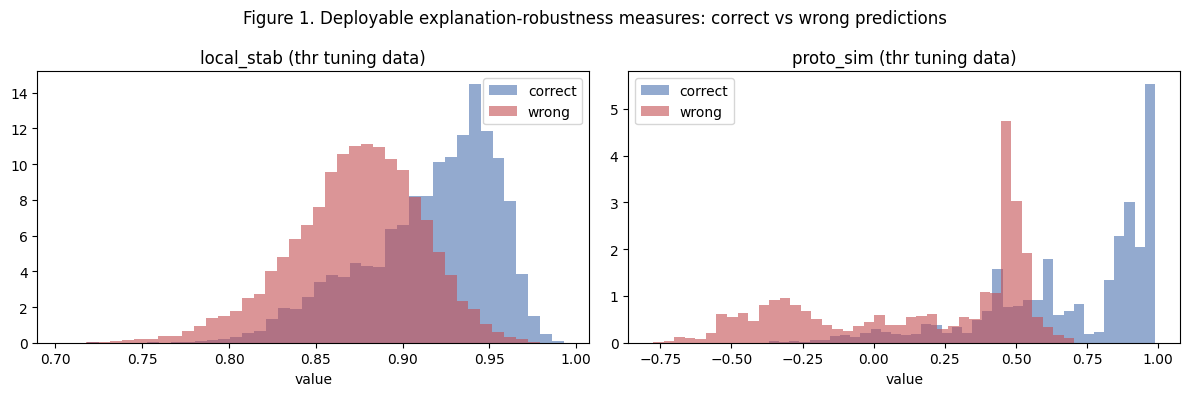

> #### Findings
> | Check | Result |
> |---|---|
> | Indicator AUROC for errors (conf / anomaly / local / prototype) | 0.738 / 0.943 / 0.794 / 0.867 |
> | Stability measure used by the policy | **prototype similarity** |
> | Spearman ρ with Part 3's clean-vs-attacked τ (local / prototype) | 0.408 / 0.472 (n = 17,830) |
>
> **Meaning:** an AUROC above 0.5 means the indicator ranks wrong predictions as less trustworthy than correct ones. The correlation with Part 3's measure shows whether the deployable indicator sees the same explanation damage.


In [80]:
TUNE = ((F["set"] == "thr") & (F["group"] != "zoo_direct")).to_numpy()
def anomaly_agreement(D):
    p = D["anomaly_p"].to_numpy()
    return np.where(D["pred"].to_numpy() == BENIGN_ID, p, 1 - p)   # high = the anomaly detector agrees with the verdict
def auroc_err(score, mask):
    y = F["is_error"].to_numpy()[mask]
    return float(roc_auc_score(y, -score[mask])) if 0 < y.sum() < len(y) else np.nan

SIG_AUC = pd.DataFrame({
    "indicator": ["confidence", "anomaly agreement", "local robustness", "prototype similarity"],
    "AUROC (thr tuning data)": [auroc_err(F["conf"].to_numpy(), TUNE), auroc_err(anomaly_agreement(F), TUNE),
                                auroc_err(F["local_stab"].to_numpy(), TUNE), auroc_err(F["proto_sim"].to_numpy(), TUNE)]})
STAB_VARIANT = "local_stab" if (np.nan_to_num(SIG_AUC.iloc[2, 1]) >= np.nan_to_num(SIG_AUC.iloc[3, 1])) else "proto_sim"
STAB_NAME = {"local_stab": "local robustness", "proto_sim": "prototype similarity"}[STAB_VARIANT]
F["stability"] = F[STAB_VARIANT]
display(SIG_AUC.round(4))

R3 = STAB_REF[STAB_REF["model"].astype(str) == POLICY_MODEL].copy()
R3["attack"] = R3["attack"].astype(str); R3["eps"] = R3["eps"].astype(float).round(6)
R3["target"] = np.where(R3["attack"] == "zoo", POLICY_MODEL, "none")
R3 = R3.merge(F.loc[F["set"] == "test", ["attack", "target", "eps", "row_id", "proto_sim", "local_stab"]],
              on=["attack", "target", "eps", "row_id"], how="inner")
REF_CORR = {v: (float(spearmanr(R3[v], R3["kendall_tau"]).statistic) if len(R3) > 2 else np.nan) for v in ["local_stab", "proto_sim"]}

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
T_ = F[TUNE]
for ax, v in zip(axes, ["local_stab", "proto_sim"]):
    for lab, m, c in [("correct", ~T_["is_error"], "#4C72B0"), ("wrong", T_["is_error"], "#C44E52")]:
        ax.hist(T_.loc[m, v], bins=40, alpha=0.6, density=True, color=c, label=lab)
    ax.set_title(f"{v} (thr tuning data)"); ax.set_xlabel("value"); ax.legend()
plt.suptitle("Figure 1. Deployable explanation-robustness measures: correct vs wrong predictions"); savefig("01_stability_measures.png")
findings([("Indicator AUROC for errors (conf / anomaly / local / prototype)", " / ".join(f"{v:.3f}" for v in SIG_AUC.iloc[:, 1])),
          ("Stability measure used by the policy", f"**{STAB_NAME}**"),
          ("Spearman ρ with Part 3's clean-vs-attacked τ (local / prototype)",
           f"{REF_CORR['local_stab']:.3f} / {REF_CORR['proto_sim']:.3f} (n = {len(R3):,})")],
         "an AUROC above 0.5 means the indicator ranks wrong predictions as less trustworthy than correct ones. "
         "The correlation with Part 3's measure shows whether the deployable indicator sees the same explanation damage.")

## 4.6 · The decision policy
For each flow, four checks are evaluated:

| Check | Fails when | Indicator |
|---|---|---|
| low confidence | calibrated confidence < τ_c | confidence |
| **possible evasion** | the classifier says **Benign** but the anomaly p-value < α | classifier ↔ anomaly disagreement |
| unsupported alarm | the classifier says **attack** but the anomaly p-value > β | classifier ↔ anomaly disagreement |
| unstable explanation | stability < τ_s | explanation robustness |

**Decision:** *accept* if no check fails; *flag* (send for more evidence, e.g. the agents of Part 5) if one check fails; *escalate* (send to a human analyst) if two or more checks fail **or** the possible-evasion check fails, because a missed attack is the costliest error.

**Tuning.** For each false-flag budget *b*, thresholds are searched on the tuning data to **maximise the share of wrong predictions that are not accepted**, subject to at most *b* of the correctly classified **clean** flows being flagged (the analyst-workload constraint of normal operation). Ties go to the setting that flags fewer flows overall. Every check can be switched off by the search, so an indicator is used only if it helps.

**Learned combiner.** As a more complex alternative, a logistic regression on the same indicators predicts "this prediction is wrong"; flows above the clean-traffic risk quantile set by the budget are flagged, and above a stricter quantile escalated. If it does not beat the transparent rule, the rule is preferred.

**Ablation.** The rule is tuned separately for every subset of the three trust indicators, so each indicator's contribution can be measured.

In [81]:
SUBSETS = ["conf", "anom", "stab", "conf+anom", "conf+stab", "anom+stab", "conf+anom+stab"]
FULL = "conf+anom+stab"

def rule_decisions(D, prm):
    conf, pred, pv, st = (D["conf"].to_numpy(), D["pred"].to_numpy(), D["anomaly_p"].to_numpy(), D["stability"].to_numpy())
    reasons = {"low_confidence": conf < prm["tau_conf"],
               "possible_evasion": (pred == BENIGN_ID) & (pv < prm["alpha"]),
               "unsupported_alarm": (pred != BENIGN_ID) & (pv > prm["beta"]),
               "unstable_explanation": st < prm["tau_stab"]}
    n = sum(v.astype(int) for v in reasons.values())
    dec = np.full(len(D), "accept", dtype=object)
    dec[n == 1] = "flag"; dec[(n >= 2) | reasons["possible_evasion"]] = "escalate"
    return dec, reasons

T = F[TUNE].reset_index(drop=True)
c_T, pr_T, p_T, s_T = (T[c].to_numpy() for c in ["conf", "pred", "anomaly_p", "stability"])
err_T = T["is_error"].to_numpy(); cc_T = ((T["variant"] == "clean") & ~T["is_error"]).to_numpy()
CONF_GRID = np.unique(np.r_[-np.inf, np.quantile(c_T, CONF_QUANTILES[1:])])
STAB_GRID = np.unique(np.r_[-np.inf, np.quantile(s_T, STAB_QUANTILES[1:])])

def tune_rule(use, budget):
    tcs = CONF_GRID if "conf" in use else np.array([-np.inf])
    tss = STAB_GRID if "stab" in use else np.array([-np.inf])
    As, Bs = (ALPHA_GRID, BETA_GRID) if "anom" in use else ([0.0], [1.01])
    LC = c_T[None, :] < tcs[:, None]; US = s_T[None, :] < tss[:, None]
    best, best_key = None, None
    for a in As:
        EV = (pr_T == BENIGN_ID) & (p_T < a)
        for b in Bs:
            base = EV | ((pr_T != BENIGN_ID) & (p_T > b))
            for i, tc in enumerate(tcs):
                flagged = (LC[i] | base)[None, :] | US
                ff = flagged[:, cc_T].mean(1); caught = flagged[:, err_T].mean(1); fr = flagged.mean(1)
                for j in np.flatnonzero(ff <= budget + 1e-12):
                    key = (round(float(caught[j]), 6), -float(fr[j]))
                    if best_key is None or key > best_key:
                        best_key = key
                        best = {"tau_conf": float(tcs[i]), "alpha": float(a), "beta": float(b), "tau_stab": float(tss[j]),
                                "tune_errors_caught": float(caught[j]), "tune_clean_false_flag": float(ff[j]), "tune_flag_rate": float(fr[j])}
    return best

def comb_features(D):
    lp = np.log10(np.clip(D["anomaly_p"].to_numpy(), 1e-6, 1)); pb = (D["pred"].to_numpy() == BENIGN_ID).astype(float)
    return np.c_[D["conf"].to_numpy(), lp, pb, pb * lp, D["stability"].to_numpy()]
COMBINER = make_pipeline(StandardScaler(), LogisticRegression(max_iter=5000, class_weight="balanced")).fit(comb_features(T), err_T)
risk_T = COMBINER.predict_proba(comb_features(T))[:, 1]

t0 = time.time(); POLICIES = {}
for budget in FALSE_FLAG_BUDGETS:
    for s in SUBSETS:
        POLICIES[(s, budget)] = {"kind": "rule", **tune_rule(s.split("+"), budget)}
    POLICIES[("learned", budget)] = {"kind": "learned", "t_flag": float(np.quantile(risk_T[cc_T], 1 - budget)),
                                     "t_escalate": float(np.quantile(risk_T[cc_T], 1 - budget * ESCALATE_SHARE))}
print(f"tuning took {time.time() - t0:.1f} s")

def decide(name, budget, D):
    prm = POLICIES[(name, budget)]
    if prm["kind"] == "learned":
        r = COMBINER.predict_proba(comb_features(D))[:, 1]
        dec = np.where(r > prm["t_escalate"], "escalate", np.where(r > prm["t_flag"], "flag", "accept")).astype(object)
        return dec, None
    return rule_decisions(D, prm)

THRESHOLDS = pd.DataFrame([{"policy": s, "budget": b, **{k: v for k, v in prm.items() if k != "kind"}} for (s, b), prm in POLICIES.items()])
display(THRESHOLDS.round(4))
P0 = POLICIES[(FULL, PRIMARY_BUDGET)]
coef = dict(zip(["conf", "log10_anomaly_p", "pred_benign", "pred_benign×log10_p", "stability"],
                COMBINER[-1].coef_[0].round(3)))
findings([("Full rule at the primary budget", f"τ_c = {P0['tau_conf']:.4f}, α = {P0['alpha']}, β = {P0['beta']}, τ_s = {P0['tau_stab']:.4f}"),
          ("Checks switched on by the tuning", ", ".join(n for n, on in [("confidence", np.isfinite(P0['tau_conf'])),
                                                                        ("possible evasion", P0['alpha'] > 0),
                                                                        ("unsupported alarm", P0['beta'] <= 1),
                                                                        ("stability", np.isfinite(P0['tau_stab']))] if on) or "none"),
          ("Tuning data: errors caught / clean false-flag rate", f"{P0['tune_errors_caught']:.3f} / {P0['tune_clean_false_flag']:.3f}"),
          ("Learned combiner coefficients (standardised)", ", ".join(f"{k} {v}" for k, v in coef.items()))],
         "thresholds come from thr-lite only, and the adaptive attack on the policy detector was not used to choose them.")

tuning took 1.7 s


,policy,budget,tau_conf,alpha,beta,tau_stab,tune_errors_caught,tune_clean_false_flag,tune_flag_rate,t_flag,t_escalate
0,conf,0.05,0.9541,0.00,1.01,-inf,0.4553,0.0464,0.2800,NaN,NaN
1,anom,0.05,-inf,0.05,0.95,-inf,0.8582,0.0089,0.2847,NaN,NaN
2,stab,0.05,-inf,0.00,1.01,0.1604,0.4198,0.0476,0.1800,NaN,NaN
3,conf+anom,0.05,0.9223,0.05,0.95,-inf,0.9604,0.0470,0.4286,NaN,NaN
4,conf+stab,0.05,0.9405,0.00,1.01,-0.1523,0.5174,0.0464,0.2916,NaN,NaN
5,anom+stab,0.05,-inf,0.05,0.95,0.0895,0.9193,0.0452,0.3403,NaN,NaN
6,conf+anom+stab,0.05,0.9223,0.05,0.95,-0.2490,0.9660,0.0476,0.4313,NaN,NaN
7,learned,0.05,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.1690,0.5971
8,conf,0.10,0.9647,0.00,1.01,-inf,0.4784,0.0565,0.3000,NaN,NaN
9,anom,0.10,-inf,0.05,0.95,-inf,0.8582,0.0089,0.2847,NaN,NaN


> #### Findings
> | Check | Result |
> |---|---|
> | Full rule at the primary budget | τ_c = 0.9223, α = 0.05, β = 0.95, τ_s = -0.2490 |
> | Checks switched on by the tuning | confidence, possible evasion, unsupported alarm, stability |
> | Tuning data: errors caught / clean false-flag rate | 0.966 / 0.048 |
> | Learned combiner coefficients (standardised) | conf -0.574, log10_anomaly_p -0.743, pred_benign -0.194, pred_benign×log10_p -4.15, stability -1.514 |
>
> **Meaning:** thresholds come from thr-lite only, and the adaptive attack on the policy detector was not used to choose them.


## 4.7 · Evaluation on test-lite (reported once)
Metrics per group, with the thresholds fixed from Section 4.6:

| Metric | Meaning |
|---|---|
| `coverage` | share of flows accepted automatically |
| `errors_caught` | share of the policy detector's wrong predictions that were flagged or escalated (**RQ2**) |
| `evasions_caught` | the same for successful evasions (attack flow classified Benign) |
| `flag_precision` | share of flagged/escalated flows whose prediction was actually wrong |
| `accepted_error_rate` | error rate among accepted flows (the residual risk) |
| `sel_macro_f1` / `full_macro_f1` | macro-F1 on accepted flows / on all flows |
| `clean_false_flag` | share of correct clean flows flagged (analyst workload) |
| `escalated` | share of flows escalated to a human |

group,attacked (all),clean,heuristic,noise,zoo_direct,zoo_transfer
errors_caught (budget 0.05),,,,,,
conf,0.4142,0.87,0.7201,0.5238,0.3012,0.3521
anom,0.8616,0.05,0.6038,0.8330,0.8255,0.9604
conf+anom,0.9539,0.84,0.9464,0.9526,0.9094,0.9810
conf+anom+stab,0.9598,0.90,0.9671,0.9588,0.9139,0.9837
learned,0.9950,0.92,0.9869,0.9936,0.9953,0.9975


group,attacked (all),clean,heuristic,noise,zoo_direct,zoo_transfer
evasions_caught (budget 0.05),,,,,,
conf,0.3893,0.8866,0.6372,0.4967,0.2998,0.3489
anom,0.9004,0.0515,0.8103,0.8823,0.8272,0.9654
conf+anom,0.9552,0.8557,0.9558,0.9536,0.9094,0.9811
conf+anom+stab,0.9609,0.9175,0.9814,0.9593,0.9137,0.9836
learned,0.9978,0.9278,1.0000,0.9989,0.9960,0.9980


group,attacked (all),clean,heuristic,noise,zoo_direct,zoo_transfer
coverage (budget 0.05),,,,,,
conf,0.6705,0.9073,0.6426,0.6203,0.7234,0.6832
anom,0.6400,0.9914,0.8477,0.6815,0.5723,0.5492
conf+anom,0.4643,0.9136,0.5954,0.4731,0.4209,0.4162
conf+anom+stab,0.4608,0.9088,0.5893,0.4695,0.4176,0.4138
learned,0.5296,0.9213,0.6662,0.5466,0.4548,0.4903


group,attacked (all),clean,heuristic,noise,zoo_direct,zoo_transfer
sel_macro_f1 (budget 0.05),,,,,,
conf,0.5201,0.9915,0.7114,0.5622,0.4139,0.4702
anom,0.8879,0.9515,0.8661,0.8975,0.8182,0.9475
conf+anom,0.8349,0.9892,0.8143,0.7810,0.6572,0.8753
conf+anom+stab,0.8497,0.9936,0.8176,0.7843,0.6641,0.8860
learned,0.9686,0.9954,0.9725,0.9661,0.9165,0.9753


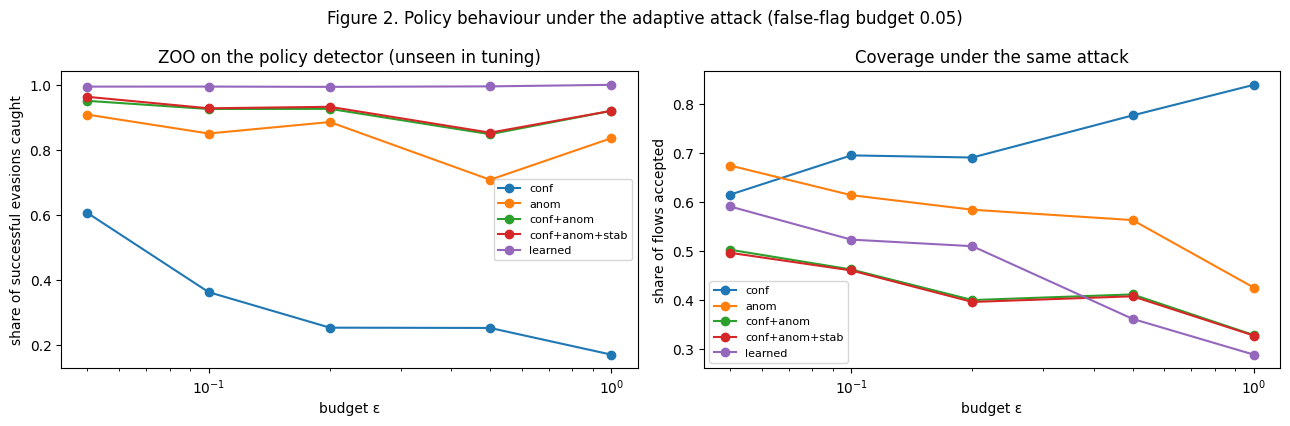

> #### Findings
> | Check | Result |
> |---|---|
> | Clean test: coverage / false-flag rate (full rule) | 0.909 / 0.050 |
> | Attacked test: errors caught (conf only → full rule → learned) | 0.414 → 0.960 → 0.995 |
> | Adaptive ZOO: evasions caught (conf only → full rule → learned) | 0.300 → 0.914 → 0.996 |
> | Attacked test: macro-F1 of accepted flows vs all flows (full rule) | 0.850 vs 0.602 |
>
> **Meaning:** errors_caught is the core RQ2 quantity: the share of wrong decisions the mechanism keeps away from automatic acceptance.


In [82]:
TEST = F[F["set"] == "test"].reset_index(drop=True)
GROUPS = {"clean": TEST["group"].eq("clean"), "noise": TEST["group"].eq("noise"), "heuristic": TEST["group"].eq("heuristic"),
          "zoo_transfer": TEST["group"].eq("zoo_transfer"), "zoo_direct": TEST["group"].eq("zoo_direct"),
          "attacked (all)": TEST["variant"].eq("attacked")}

def metrics(D, dec):
    acc = dec == "accept"; err = D["is_error"].to_numpy(); ev = D["is_evasion"].to_numpy()
    y, p = D["y"].to_numpy(), D["pred"].to_numpy(); cc = ((D["variant"] == "clean") & ~D["is_error"]).to_numpy()
    return {"coverage": acc.mean(), "escalated": (dec == "escalate").mean(),
            "errors_caught": (~acc[err]).mean() if err.any() else np.nan,
            "evasions_caught": (~acc[ev]).mean() if ev.any() else np.nan,
            "flag_precision": err[~acc].mean() if (~acc).any() else np.nan,
            "accepted_error_rate": err[acc].mean() if acc.any() else np.nan,
            "sel_macro_f1": macro_f1(y[acc], p[acc], K) if acc.any() else np.nan,
            "full_macro_f1": macro_f1(y, p, K),
            "clean_false_flag": (~acc[cc]).mean() if cc.any() else np.nan}

DEC_TEST = {(n, b): decide(n, b, TEST)[0] for (n, b) in POLICIES}
EVAL = pd.DataFrame([{"policy": n, "budget": b, "group": g, **metrics(TEST[m], DEC_TEST[(n, b)][m.to_numpy()])}
                     for (n, b) in POLICIES for g, m in GROUPS.items()])
MAIN = ["conf", "anom", "conf+anom", FULL, "learned"]
view = EVAL[(EVAL.budget == PRIMARY_BUDGET) & EVAL.policy.isin(MAIN)]
for col in ["errors_caught", "evasions_caught", "coverage", "sel_macro_f1"]:
    display(view.pivot(index="policy", columns="group", values=col).loc[MAIN].round(4).rename_axis(f"{col} (budget {PRIMARY_BUDGET})"))

# evasions caught on the adaptive attack, by budget ε
zd = TEST["group"].eq("zoo_direct").to_numpy()
fig, axes = plt.subplots(1, 2, figsize=(13, 4.3))
for n in MAIN:
    dec = DEC_TEST[(n, PRIMARY_BUDGET)]
    rows = [(e, metrics(TEST[zd & (TEST.eps == e).to_numpy()], dec[zd & (TEST.eps == e).to_numpy()])) for e in sorted(TEST.loc[zd, "eps"].unique())]
    axes[0].plot([e for e, _ in rows], [r["evasions_caught"] for _, r in rows], marker="o", label=n)
    axes[1].plot([e for e, _ in rows], [r["coverage"] for _, r in rows], marker="o", label=n)
axes[0].set(xlabel="budget ε", ylabel="share of successful evasions caught", title="ZOO on the policy detector (unseen in tuning)")
axes[1].set(xlabel="budget ε", ylabel="share of flows accepted", title="Coverage under the same attack")
for ax in axes: ax.set_xscale("log"); ax.legend(fontsize=8)
plt.suptitle(f"Figure 2. Policy behaviour under the adaptive attack (false-flag budget {PRIMARY_BUDGET})"); savefig("02_policy_under_attack.png")

def g(n, grp, col, b=PRIMARY_BUDGET):
    return float(EVAL[(EVAL.policy == n) & (EVAL.budget == b) & (EVAL.group == grp)][col].iloc[0])
findings([("Clean test: coverage / false-flag rate (full rule)", f"{g(FULL, 'clean', 'coverage'):.3f} / {g(FULL, 'clean', 'clean_false_flag'):.3f}"),
          ("Attacked test: errors caught (conf only → full rule → learned)",
           f"{g('conf', 'attacked (all)', 'errors_caught'):.3f} → {g(FULL, 'attacked (all)', 'errors_caught'):.3f} → {g('learned', 'attacked (all)', 'errors_caught'):.3f}"),
          ("Adaptive ZOO: evasions caught (conf only → full rule → learned)",
           f"{g('conf', 'zoo_direct', 'evasions_caught'):.3f} → {g(FULL, 'zoo_direct', 'evasions_caught'):.3f} → {g('learned', 'zoo_direct', 'evasions_caught'):.3f}"),
          ("Attacked test: macro-F1 of accepted flows vs all flows (full rule)",
           f"{g(FULL, 'attacked (all)', 'sel_macro_f1'):.3f} vs {g(FULL, 'attacked (all)', 'full_macro_f1'):.3f}")],
         "errors_caught is the core RQ2 quantity: the share of wrong decisions the mechanism keeps away from automatic acceptance.")

## 4.8 · Ablation: which indicators earn their place?
Every subset of the three trust indicators, each tuned with the same objective and budget. An indicator earns its place if adding it raises the errors or evasions caught at equal clean false-flag rate.

In [83]:
ABL = []
for (n, b) in POLICIES:
    r = {"policy": n, "budget": b}
    for grp, col in [("clean", "clean_false_flag"), ("clean", "coverage"), ("attacked (all)", "errors_caught"),
                     ("zoo_direct", "evasions_caught"), ("attacked (all)", "coverage"), ("attacked (all)", "sel_macro_f1")]:
        r[f"{grp}: {col}"] = g(n, grp, col, b)
    ABL.append(r)
ABL = pd.DataFrame(ABL).set_index(["budget", "policy"]).round(4)
display(ABL)
full_vs_ca = ABL.loc[(PRIMARY_BUDGET, FULL), "attacked (all): errors_caught"] - ABL.loc[(PRIMARY_BUDGET, "conf+anom"), "attacked (all): errors_caught"]
best_subset = ABL.loc[PRIMARY_BUDGET].drop(index="learned")["attacked (all): errors_caught"].idxmax()
findings([("Best rule subset on attacked test (errors caught)", best_subset),
          ("Gain from adding stability to confidence + anomaly", f"{full_vs_ca:+.4f}"),
          ("Gain from adding anomaly to confidence", f"{ABL.loc[(PRIMARY_BUDGET, 'conf+anom'), 'attacked (all): errors_caught'] - ABL.loc[(PRIMARY_BUDGET, 'conf'), 'attacked (all): errors_caught']:+.4f}")],
         "whether these gains are larger than chance is tested with the flow-level bootstrap in Section 4.10.")

clean: clean_false_flag  clean: coverage  attacked (all): errors_caught  zoo_direct: evasions_caught  attacked (all): coverage  attacked (all): sel_macro_f1
budget policy                                                                                                                                                                      
0.05   conf                             0.0535           0.9073                         0.4142                       0.2998                    0.6705                        0.5201
       anom                             0.0066           0.9914                         0.8616                       0.8272                    0.6400                        0.8879
       stab                             0.0363           0.9213                         0.4265                       0.3128                    0.7866                        0.6767
       conf+anom                        0.0484           0.9136                         0.9539                       0.9094                    0.4643                        0.8349
       conf+stab                        0.0514           0.9073                         0.4894                       0.3593                    0.6500                        0.5540
       anom+stab                        0.0358           0.9208                         0.9274                       0.8977                    0.5827                        0.8690
       conf+anom+stab                   0.0504           0.9088                         0.9598                       0.9137                    0.4608                        0.8497
       learned                          0.0363           0.9213                         0.9950                       0.9960                    0.5296                        0.9686
0.10   conf                             0.0721           0.8881                         0.4354                       0.3228                    0.6502                        0.5134
       anom                             0.0066           0.9914                         0.8616                       0.8272                    0.6400                        0.8879
       stab                             0.0499           0.9069                         0.4729                       0.3486                    0.7492                        0.6781
       conf+anom                        0.0787           0.8819                         0.9655                       0.9263                    0.4263                        0.7521
       conf+stab                        0.1054           0.8545                         0.5748                       0.4498                    0.5749                        0.5314
       anom+stab                        0.0550           0.9021                         0.9556                       0.9028                    0.5463                        0.8613
       conf+anom+stab                   0.1019           0.8579                         0.9745                       0.9401                    0.4129                        0.7572
       learned                          0.0862           0.8728                         0.9995                       1.0000                    0.4534                        0.9447

> #### Findings
> | Check | Result |
> |---|---|
> | Best rule subset on attacked test (errors caught) | conf+anom+stab |
> | Gain from adding stability to confidence + anomaly | +0.0059 |
> | Gain from adding anomaly to confidence | +0.5397 |
>
> **Meaning:** whether these gains are larger than chance is tested with the flow-level bootstrap in Section 4.10.


## 4.9 · Risk–coverage curves and AURC
Flows are ranked from most to least trustworthy by each score, and the error rate of the accepted part (risk) is plotted as more flows are accepted (coverage). Lower area under the curve (AURC) is better (Geifman and El-Yaniv, 2017).

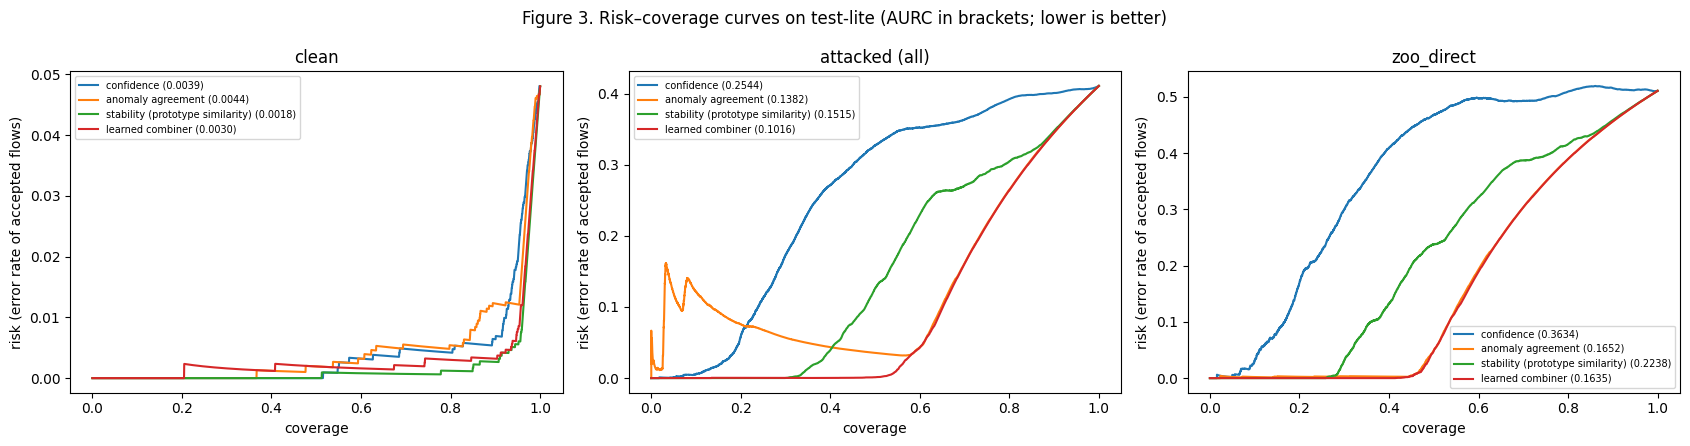

group,attacked (all),clean,zoo_direct
score,,,
anomaly agreement,0.13817,0.00444,0.16525
confidence,0.25444,0.00389,0.36341
learned combiner,0.10161,0.00300,0.16352
stability (prototype similarity),0.15149,0.00184,0.22381


> #### Findings
> | Check | Result |
> |---|---|
> | Lowest AURC on attacked flows | learned combiner |


In [84]:
def aurc(trust, err):
    order = np.argsort(-trust, kind="stable"); e = err[order].astype(float)
    risk = np.cumsum(e) / np.arange(1, len(e) + 1); return float(risk.mean()), risk
SCORES = {"confidence": lambda D: D["conf"].to_numpy(), "anomaly agreement": anomaly_agreement,
          f"stability ({STAB_NAME})": lambda D: D["stability"].to_numpy(),
          "learned combiner": lambda D: -COMBINER.predict_proba(comb_features(D))[:, 1]}
AURC, fig = [], plt.figure(figsize=(17, 4.5))
for i, grp in enumerate(["clean", "attacked (all)", "zoo_direct"]):
    D = TEST[GROUPS[grp]]; err = D["is_error"].to_numpy(); ax = fig.add_subplot(1, 3, i + 1)
    for name, fn in SCORES.items():
        a, risk = aurc(fn(D), err); AURC.append({"group": grp, "score": name, "AURC": a, "risk_at_full_coverage": err.mean()})
        ax.plot(np.arange(1, len(risk) + 1) / len(risk), risk, label=f"{name} ({a:.4f})")
    ax.set(xlabel="coverage", ylabel="risk (error rate of accepted flows)", title=grp); ax.legend(fontsize=7)
plt.suptitle("Figure 3. Risk–coverage curves on test-lite (AURC in brackets; lower is better)"); savefig("03_risk_coverage.png")
AURC = pd.DataFrame(AURC); display(AURC.pivot(index="score", columns="group", values="AURC").round(5))
best_att = AURC[AURC.group == "attacked (all)"].set_index("score")["AURC"].idxmin()
findings([("Lowest AURC on attacked flows", best_att)])

## 4.10 · Flow-level paired bootstrap
The same flow appears in up to 26 versions (clean and every attack configuration), so versions are not independent. The bootstrap therefore resamples **flows** (all versions of a drawn flow are kept together) and compares two policies on the same draw. A difference whose 95% interval excludes 0 is reported as established.

In [85]:
COMPARE = [(FULL, "conf"), (FULL, "conf+anom"), (FULL, "anom"), ("learned", FULL)]
rid = TEST["row_id"].to_numpy(); uid, inv = np.unique(rid, return_inverse=True)
order = np.argsort(inv, kind="stable"); MEMBERS = np.split(order, np.cumsum(np.bincount(inv))[:-1])
att_m, zd_m = GROUPS["attacked (all)"].to_numpy(), GROUPS["zoo_direct"].to_numpy()
err_a, ev_a = TEST["is_error"].to_numpy(), TEST["is_evasion"].to_numpy()
cc_a = ((TEST["variant"] == "clean") & ~TEST["is_error"]).to_numpy()
y_a, p_a = TEST["y"].to_numpy(), TEST["pred"].to_numpy()

def stats(dec, idx):
    acc = dec[idx] == "accept"; a, z, c = att_m[idx], zd_m[idx], cc_a[idx]; e, v = err_a[idx], ev_a[idx]
    m1 = a & e; m2 = z & v; m3 = a & acc
    return np.array([(~acc[m1]).mean() if m1.any() else np.nan, (~acc[m2]).mean() if m2.any() else np.nan,
                     (~acc[c]).mean() if c.any() else np.nan,
                     macro_f1(y_a[idx][m3], p_a[idx][m3], K) if m3.any() else np.nan])
STAT_NAMES = ["attacked: errors caught", "zoo_direct: evasions caught", "clean: false-flag rate", "attacked: accepted macro-F1"]
BOOT, full_idx, t0 = [], np.arange(len(TEST)), time.time()
for a, b in COMPARE:
    da, db = DEC_TEST[(a, PRIMARY_BUDGET)], DEC_TEST[(b, PRIMARY_BUDGET)]
    point = stats(da, full_idx) - stats(db, full_idx)
    r = np.random.default_rng(SEED)        # same flow draws for every comparison
    D = []
    for _ in range(N_BOOT):
        ix = np.concatenate([MEMBERS[i] for i in r.integers(0, len(MEMBERS), len(MEMBERS))])
        D.append(stats(da, ix) - stats(db, ix))
    D = np.array(D)
    for k, nm in enumerate(STAT_NAMES):
        lo, hi = np.nanpercentile(D[:, k], [2.5, 97.5])
        BOOT.append({"comparison": f"{a} minus {b}", "metric": nm, "difference": point[k], "ci_low": lo, "ci_high": hi,
                     "established": bool(lo > 0 or hi < 0)})
BOOT = pd.DataFrame(BOOT); display(BOOT.round(4)); print(f"({time.time() - t0:.0f} s)")
def est(a, b, metric):
    r_ = BOOT[(BOOT.comparison == f"{a} minus {b}") & (BOOT.metric == metric)].iloc[0]
    return f"{r_.difference:+.3f} [{r_.ci_low:+.3f}, {r_.ci_high:+.3f}] " + ("✔ established" if r_.established else "not established")
findings([("Full rule − confidence only: attacked errors caught", est(FULL, "conf", STAT_NAMES[0])),
          ("Full rule − confidence + anomaly: attacked errors caught (value of stability)", est(FULL, "conf+anom", STAT_NAMES[0])),
          ("Full rule − anomaly only: attacked errors caught", est(FULL, "anom", STAT_NAMES[0])),
          ("Learned − full rule: attacked errors caught", est("learned", FULL, STAT_NAMES[0]))],
         f"{N_BOOT} resamples of {len(MEMBERS):,} test flows; budget {PRIMARY_BUDGET}.")

,comparison,metric,difference,ci_low,ci_high,established
0,conf+anom+stab minus conf,attacked: errors caught,0.5457,0.5332,0.5577,True
1,conf+anom+stab minus conf,zoo_direct: evasions caught,0.6139,0.5962,0.6322,True
2,conf+anom+stab minus conf,clean: false-flag rate,-0.0030,-0.0095,0.0031,False
3,conf+anom+stab minus conf,attacked: accepted macro-F1,0.3296,0.2975,0.3570,True
4,conf+anom+stab minus conf+anom,attacked: errors caught,0.0059,0.0045,0.0075,True
5,conf+anom+stab minus conf+anom,zoo_direct: evasions caught,0.0043,0.0025,0.0064,True
6,conf+anom+stab minus conf+anom,clean: false-flag rate,0.0020,0.0005,0.0041,True
7,conf+anom+stab minus conf+anom,attacked: accepted macro-F1,0.0148,0.0112,0.0183,True
8,conf+anom+stab minus anom,attacked: errors caught,0.0983,0.0910,0.1058,True
9,conf+anom+stab minus anom,zoo_direct: evasions caught,0.0865,0.0768,0.0959,True


(29 s)


> #### Findings
> | Check | Result |
> |---|---|
> | Full rule − confidence only: attacked errors caught | +0.546 [+0.533, +0.558] ✔ established |
> | Full rule − confidence + anomaly: attacked errors caught (value of stability) | +0.006 [+0.005, +0.007] ✔ established |
> | Full rule − anomaly only: attacked errors caught | +0.098 [+0.091, +0.106] ✔ established |
> | Learned − full rule: attacked errors caught | +0.035 [+0.030, +0.040] ✔ established |
>
> **Meaning:** 1000 resamples of 2,083 test flows; budget 0.05.


## 4.11 · Unseen attack families
Heartbleed and Infiltration were removed before training (Part 1). The classifier cannot name them, so the desired outcome is that the mechanism does **not** accept them automatically.

In [86]:
UN = F[F["group"] == "unseen"].reset_index(drop=True)
UNSEEN = []
for n in ["conf", "conf+anom", FULL, "learned"]:
    dec = decide(n, PRIMARY_BUDGET, UN)[0]
    for fam, m in UN.groupby("family").groups.items():
        d = dec[np.asarray(m)]
        UNSEEN.append({"policy": n, "family": fam, "flows": len(d), "accepted": (d == "accept").mean(),
                       "flagged": (d == "flag").mean(), "escalated": (d == "escalate").mean()})
UNSEEN = pd.DataFrame(UNSEEN); display(UNSEEN.round(3))
display(pd.crosstab(UN["family"], np.array(CLASSES)[UN["pred"]]).rename_axis(index="unseen family", columns=f"{POLICY_MODEL} predicts"))
un_full = UNSEEN[UNSEEN.policy == FULL]
findings([(f"{r.family}: not accepted (full rule)", f"{1 - r.accepted:.0%} of {r.flows}") for r in un_full.itertuples()],
         "flows of families the classifier has never seen should reach an analyst rather than be labelled automatically.")

,policy,family,flows,accepted,flagged,escalated
0,conf,Heartbleed,11,0.364,0.636,0.000
1,conf,Infiltration,36,1.000,0.000,0.000
2,conf+anom,Heartbleed,11,0.000,0.000,1.000
3,conf+anom,Infiltration,36,0.083,0.000,0.917
4,conf+anom+stab,Heartbleed,11,0.000,0.000,1.000
5,conf+anom+stab,Infiltration,36,0.083,0.000,0.917
6,learned,Heartbleed,11,0.000,0.000,1.000
7,learned,Infiltration,36,0.028,0.028,0.944


xgb predicts,Benign
unseen family,
Heartbleed,11
Infiltration,36


> #### Findings
> | Check | Result |
> |---|---|
> | Heartbleed: not accepted (full rule) | 100% of 11 |
> | Infiltration: not accepted (full rule) | 92% of 36 |
>
> **Meaning:** flows of families the classifier has never seen should reach an analyst rather than be labelled automatically.


## 4.12 · Comparison with the individual detectors (no rejection)

In [87]:
BASE = []
for grp, m in GROUPS.items():
    D = TEST[m]
    for mod in [POLICY_MODEL] + OTHER_MODELS:
        p = D[f"pred_{mod}"].to_numpy(); y = D["y"].to_numpy(); att = y != BENIGN_ID
        BASE.append({"system": f"classifier: {mod}", "group": grp, "macro_f1": macro_f1(y, p, K),
                     "attack_recall": (p[att] != BENIGN_ID).mean(), "benign_fpr": (p[~att] != BENIGN_ID).mean() if (~att).any() else np.nan})
    yb = D["is_attack_flow"].to_numpy().astype(int)
    BASE.append({"system": f"anomaly detector: {ANOMALY}", "group": grp,
                 "auroc_attack_vs_benign": roc_auc_score(yb, -D["anomaly_p"]) if 0 < yb.sum() < len(yb) else np.nan,
                 "attack_recall": (D.loc[yb == 1, "anomaly_p"] < CFG["anomaly_alpha"]).mean(),
                 "benign_fpr": (D.loc[yb == 0, "anomaly_p"] < CFG["anomaly_alpha"]).mean()})
BASE = pd.DataFrame(BASE); display(BASE.round(4))
nb2_f1 = float(NB2_EVAL[(NB2_EVAL.split == "test_lite") & (NB2_EVAL.model == POLICY_MODEL)]["macro_F1"].iloc[0])
here_f1 = float(BASE[(BASE.system == f"classifier: {POLICY_MODEL}") & (BASE.group == "clean")]["macro_f1"].iloc[0])
CLEAN_F1_OK = abs(nb2_f1 - here_f1) < 1e-3

,system,group,macro_f1,attack_recall,benign_fpr,auroc_attack_vs_benign
0,classifier: xgb,clean,0.9501,0.9456,0.0000,NaN
1,classifier: rf,clean,0.9223,0.9164,0.0000,NaN
2,classifier: mlp,clean,0.9184,0.9125,0.0000,NaN
3,anomaly detector: autoencoder,clean,NaN,0.4767,0.0433,0.9098
4,classifier: xgb,noise,0.6447,0.5865,0.0000,NaN
5,classifier: rf,noise,0.4400,0.4042,0.0000,NaN
6,classifier: mlp,noise,0.7881,0.7511,0.0000,NaN
7,anomaly detector: autoencoder,noise,NaN,0.8101,0.0433,0.9741
8,classifier: xgb,heuristic,0.7471,0.7895,0.0000,NaN
9,classifier: rf,heuristic,0.4761,0.4515,0.0000,NaN


## 4.13 · Cost of the mechanism (RQ4 input)
Per-flow latency of every component the mechanism needs, from Part 2's measurements and from this part. Part 5 adds the cost of the agents.

In [88]:
D_b = TEST.sample(min(2000, len(TEST)), random_state=SEED)
Xb = X[D_b["version_id"].to_numpy()]
t = time.perf_counter(); calibrated_proba(Xb); pred_ms = 1e3 * (time.perf_counter() - t) / len(Xb)
t = time.perf_counter()
for _ in range(10): decide(FULL, PRIMARY_BUDGET, D_b)
rule_ms = 1e3 * (time.perf_counter() - t) / (10 * len(D_b))
t = time.perf_counter(); cosine(SP_U[:len(Xb)], PROTO[pred_u[:len(Xb)]]); proto_ms = 1e3 * (time.perf_counter() - t) / len(Xb)
stab_ms = LOCAL_EXTRA_MS if STAB_VARIANT == "local_stab" else proto_ms
COST4 = pd.DataFrame([
    {"component": f"classifier {POLICY_MODEL} + calibration (batched, this part)", "ms_per_flow": pred_ms},
    {"component": f"classifier {POLICY_MODEL}, single-flow p50 (Part 2)", "ms_per_flow": float(COST2.loc[POLICY_MODEL, "latency_ms_p50"])},
    {"component": f"anomaly detector {ANOMALY}, single-flow p50 (Part 2)", "ms_per_flow": float(COST2.loc[ANOMALY, "latency_ms_p50"])},
    {"component": "TreeSHAP of the predicted class (batched)", "ms_per_flow": SHAP_MS},
    {"component": f"stability: {STAB_NAME}", "ms_per_flow": stab_ms},
    {"component": "policy decision (thresholds)", "ms_per_flow": rule_ms}])
COST4["ms_per_flow"] = COST4["ms_per_flow"].round(4)
TOTAL_MS = float(COST2.loc[POLICY_MODEL, "latency_ms_p50"] + COST2.loc[ANOMALY, "latency_ms_p50"] + SHAP_MS + stab_ms + rule_ms)
display(COST4)
findings([("Mechanism latency per flow (single-flow models + batched explanation)", f"{TOTAL_MS:.2f} ms"),
          ("Share of clean / attacked test flows sent onward (flag or escalate)",
           f"{1 - g(FULL, 'clean', 'coverage'):.3f} / {1 - g(FULL, 'attacked (all)', 'coverage'):.3f}")],
         "only flagged and escalated flows reach the more expensive agents of Part 5.")

,component,ms_per_flow
0,"classifier xgb + calibration (batched, this part)",0.0141
1,"classifier xgb, single-flow p50 (Part 2)",8.0000
2,"anomaly detector autoencoder, single-flow p50 ...",0.5040
3,TreeSHAP of the predicted class (batched),0.2440
4,stability: prototype similarity,0.0003
5,policy decision (thresholds),0.0002


> #### Findings
> | Check | Result |
> |---|---|
> | Mechanism latency per flow (single-flow models + batched explanation) | 8.75 ms |
> | Share of clean / attacked test flows sent onward (flag or escalate) | 0.091 / 0.539 |
>
> **Meaning:** only flagged and escalated flows reach the more expensive agents of Part 5.


## 4.14 · Evidence for the agents (Part 5)
The agents receive only facts produced by the models, never the true label. Besides the three trust indicators and the other classifiers' verdicts, two further evidence items are prepared:
* the **three most influential features** of the flow's explanation (to be described with Part 1's feature dictionary);
* the **five most similar training flows** (nearest neighbours in the model input space among Part 2's prototype set of training flows) and their families.

In [89]:
XP = XC[POS.loc[proto_meta["row_id"]].to_numpy()]
NN = NearestNeighbors(n_neighbors=KNN_K).fit(XP)
ix = F.index[F["set"].isin(["test", "unseen"])].to_numpy()
dist, nb = NN.kneighbors(X[ix])
labs = proto_meta["label_id"].to_numpy()[nb]
maj = np.array([np.bincount(row, minlength=K).argmax() for row in labs])
F.loc[ix, "knn_families"] = [",".join(CLASSES[l] for l in row) for row in labs]
F.loc[ix, "knn_majority"] = np.array(CLASSES)[maj]
F.loc[ix, "knn_agree"] = (labs == maj[:, None]).mean(1)
F.loc[ix, "knn_median_distance"] = np.median(dist, axis=1)
agree_pred = (F.loc[ix, "knn_majority"].to_numpy() == np.array(CLASSES)[F.loc[ix, "pred"].clip(0).to_numpy()])
findings([("Test flow versions with similar-case evidence", f"{len(ix):,}"),
          ("Similar-case majority agrees with the policy detector", f"{agree_pred.mean():.3f}")])

> #### Findings
> | Check | Result |
> |---|---|
> | Test flow versions with similar-case evidence | 54,205 |
> | Similar-case majority agrees with the policy detector | 0.609 |


## 4.15 · Answer to RQ2

In [90]:
P0 = POLICIES[(FULL, PRIMARY_BUDGET)]
on = [n for n, ok in [("low confidence", np.isfinite(P0["tau_conf"])), ("possible evasion", P0["alpha"] > 0),
                      ("unsupported alarm", P0["beta"] <= 1), ("unstable explanation", np.isfinite(P0["tau_stab"]))] if ok]
b_stab = BOOT[(BOOT.comparison == f"{FULL} minus conf+anom") & (BOOT.metric == STAT_NAMES[0])].iloc[0]
b_conf = BOOT[(BOOT.comparison == f"{FULL} minus conf") & (BOOT.metric == STAT_NAMES[0])].iloc[0]
b_lr = BOOT[(BOOT.comparison == f"learned minus {FULL}") & (BOOT.metric == STAT_NAMES[0])].iloc[0]
un_rate = 1 - (un_full["accepted"] * un_full["flows"]).sum() / max(un_full["flows"].sum(), 1)
display(Markdown(f"""> #### RQ2 · Answer (generated from this run)
> **Indicators.** On the tuning data, the AUROC for recognising wrong predictions is {SIG_AUC.iloc[0, 1]:.3f} for calibrated confidence,
> {SIG_AUC.iloc[1, 1]:.3f} for classifier–anomaly agreement and {SIG_AUC.loc[SIG_AUC.indicator == STAB_NAME].iloc[0, 1]:.3f} for explanation robustness ({STAB_NAME}).
> The deployable robustness measure correlates with Part 3's clean-vs-attacked SHAP stability at ρ = {REF_CORR[STAB_VARIANT]:.2f}.
>
> **Mechanism.** At a clean false-flag budget of {PRIMARY_BUDGET:.0%}, the tuned rule uses: {", ".join(on) or "no check"}.
> On clean test flows it accepts {g(FULL, 'clean', 'coverage'):.1%} of flows and flags {g(FULL, 'clean', 'clean_false_flag'):.1%} of correct ones.
> On attacked test flows it keeps **{g(FULL, 'attacked (all)', 'errors_caught'):.1%}** of the detector's wrong predictions away from automatic acceptance
> (confidence alone: {g('conf', 'attacked (all)', 'errors_caught'):.1%}), and catches **{g(FULL, 'zoo_direct', 'evasions_caught'):.1%}** of successful evasions
> by the adaptive attack that was never used for tuning (confidence alone: {g('conf', 'zoo_direct', 'evasions_caught'):.1%}).
> Accepted attacked flows reach macro-F1 {g(FULL, 'attacked (all)', 'sel_macro_f1'):.3f}, against {g(FULL, 'attacked (all)', 'full_macro_f1'):.3f} without rejection.
>
> **Evidence strength (flow-level bootstrap).** Full rule vs confidence only: {b_conf.difference:+.3f} [{b_conf.ci_low:+.3f}, {b_conf.ci_high:+.3f}]
> ({"established" if b_conf.established else "not established"}). Adding explanation robustness to confidence + anomaly:
> {b_stab.difference:+.3f} [{b_stab.ci_low:+.3f}, {b_stab.ci_high:+.3f}] ({"established" if b_stab.established else "not established"}),
> i.e. {b_stab.difference / max(1 - g('conf+anom', 'attacked (all)', 'errors_caught'), 1e-9):.0%} of the errors that confidence + anomaly evidence miss.
> Learned combiner vs transparent rule: {b_lr.difference:+.3f} [{b_lr.ci_low:+.3f}, {b_lr.ci_high:+.3f}] ({"established" if b_lr.established else "not established"}).
>
> **Unseen families.** {un_rate:.0%} of Heartbleed and Infiltration flows are flagged or escalated rather than accepted.
>
> **Implication for RQ3.** Part 5 sends only the flagged and escalated flows to the agents and compares this routing with running the agents on every flow.
"""))

> #### RQ2 · Answer (generated from this run)
> **Indicators.** On the tuning data, the AUROC for recognising wrong predictions is 0.738 for calibrated confidence,
> 0.943 for classifier–anomaly agreement and 0.867 for explanation robustness (prototype similarity).
> The deployable robustness measure correlates with Part 3's clean-vs-attacked SHAP stability at ρ = 0.47.
>
> **Mechanism.** At a clean false-flag budget of 5%, the tuned rule uses: low confidence, possible evasion, unsupported alarm, unstable explanation.
> On clean test flows it accepts 90.9% of flows and flags 5.0% of correct ones.
> On attacked test flows it keeps **96.0%** of the detector's wrong predictions away from automatic acceptance
> (confidence alone: 41.4%), and catches **91.4%** of successful evasions
> by the adaptive attack that was never used for tuning (confidence alone: 30.0%).
> Accepted attacked flows reach macro-F1 0.850, against 0.602 without rejection.
>
> **Evidence strength (flow-level bootstrap).** Full rule vs confidence only: +0.546 [+0.533, +0.558]
> (established). Adding explanation robustness to confidence + anomaly:
> +0.006 [+0.005, +0.007] (established),
> i.e. 13% of the errors that confidence + anomaly evidence miss.
> Learned combiner vs transparent rule: +0.035 [+0.030, +0.040] (established).
>
> **Unseen families.** 94% of Heartbleed and Infiltration flows are flagged or escalated rather than accepted.
>
> **Implication for RQ3.** Part 5 sends only the flagged and escalated flows to the agents and compares this routing with running the agents on every flow.


## 4.16 · Final checks

In [91]:
checks = {
    "every attacked attack flow matched to its adversarial input": MATCH_OK,
    "recomputed probabilities reproduce Part 3": ALIGN_OK,
    "SHAP reproduces Part 2 on clean flows": bool(SHAP_OK),
    "clean test-lite macro-F1 matches Part 2": bool(CLEAN_F1_OK),
    "tuning used thr-lite only, without the adaptive attack on the policy detector":
        bool(set(T["set"]) == {"thr"} and "zoo_direct" not in set(T["group"])),
    "stability available for every flow version": bool(np.isfinite(F["stability"]).all()),
    "clean false-flag rate on tuning data within budget": all(POLICIES[(s, b)].get("tune_clean_false_flag", 0) <= b + 1e-9
                                                             for (s, b) in POLICIES if POLICIES[(s, b)]["kind"] == "rule"),
    "decisions are accept / flag / escalate only": all(set(np.unique(d)) <= {"accept", "flag", "escalate"} for d in DEC_TEST.values()),
    "unseen-family flows evaluated": int((F["group"] == "unseen").sum()) == len(UN) > 0,
}
display(pd.DataFrame([(k, "✔ pass" if v else "✘ FAIL") for k, v in checks.items()], columns=["check", "result"]))
assert all(checks.values()), "A final check failed."
findings([("Checks passed", f"{sum(checks.values())} of {len(checks)}")])

,check,result
0,every attacked attack flow matched to its adve...,✔ pass
1,recomputed probabilities reproduce Part 3,✔ pass
2,SHAP reproduces Part 2 on clean flows,✔ pass
3,clean test-lite macro-F1 matches Part 2,✔ pass
4,"tuning used thr-lite only, without the adaptiv...",✔ pass
5,stability available for every flow version,✔ pass
6,clean false-flag rate on tuning data within bu...,✔ pass
7,decisions are accept / flag / escalate only,✔ pass
8,unseen-family flows evaluated,✔ pass


> #### Findings
> | Check | Result |
> |---|---|
> | Checks passed | 9 of 9 |


## 4.17 · Saved outputs

In [92]:
dec0, rs0 = decide(FULL, PRIMARY_BUDGET, F)
F["decision"] = dec0; F["flagged"] = F["decision"] != "accept"; F["escalated"] = F["decision"] == "escalate"
for k, v in rs0.items(): F[f"reason_{k}"] = v
F["decision_learned"] = decide("learned", PRIMARY_BUDGET, F)[0]
F["learned_risk"] = COMBINER.predict_proba(comb_features(F))[:, 1]
OUT_COLS = (["version_id", "set", "group", "variant", "attack", "target", "eps", "row_id", "y", "family", "pred", "conf"]
            + [f"pred_{m}" for m in OTHER_MODELS] + [f"conf_{m}" for m in OTHER_MODELS]
            + ["anomaly_p", "stability", "local_stab", "proto_sim", "decision", "flagged", "escalated"]
            + [f"reason_{k}" for k in rs0] + ["decision_learned", "learned_risk", "is_error", "is_evasion"]
            + [f"top_feature_{k}" for k in (1, 2, 3)] + [f"top_feature_{k}_supports" for k in (1, 2, 3)]
            + ["knn_families", "knn_majority", "knn_agree", "knn_median_distance"])
F.loc[F["set"].isin(["test", "unseen"]), OUT_COLS].to_parquet(OUT_DIR / "policy_flags_test.parquet", index=False)
F.loc[F["set"] == "thr", [c for c in OUT_COLS if not c.startswith("knn")]].to_parquet(OUT_DIR / "policy_flags_thr.parquet", index=False)

SPEC = {"notebook_id": NOTEBOOK_ID, "policy_detector": POLICY_MODEL, "other_models": OTHER_MODELS, "anomaly_detector": ANOMALY,
        "class_names": CLASSES, "benign_id": BENIGN_ID, "stability_mode": "deployable", "stability_variant": STAB_VARIANT,
        "stability_noise_sd": STAB_NOISE_SD, "stability_repeats": STAB_REPEATS, "false_flag_budget": PRIMARY_BUDGET,
        "tau_conf": P0["tau_conf"], "alpha": P0["alpha"], "beta": P0["beta"], "tau_stab": P0["tau_stab"],
        "rule": "checks: conf < tau_conf; pred Benign and p < alpha (possible evasion); pred attack and p > beta "
                "(unsupported alarm); stability < tau_stab. accept if none fails; escalate if possible evasion "
                "or >= 2 fail; flag otherwise. Disabled checks have thresholds -inf / 0 / 1.01.",
        "learned_combiner": {"features": list(coef), "coef_standardised": COMBINER[-1].coef_[0].tolist(),
                             "intercept": float(COMBINER[-1].intercept_[0]),
                             "t_flag": POLICIES[("learned", PRIMARY_BUDGET)]["t_flag"],
                             "t_escalate": POLICIES[("learned", PRIMARY_BUDGET)]["t_escalate"]},
        "tuned_on": "thr-lite: clean, noise, heuristic and transferred ZOO versions (ZOO on the policy detector held out)",
        "knn_k": KNN_K}
json.dump(SPEC, open(OUT_DIR / "policy_spec.json", "w"), indent=2, default=to_builtin)
THRESHOLDS.to_csv(OUT_DIR / "thresholds_tuned_on_thr.csv", index=False); EVAL.to_csv(OUT_DIR / "policy_eval_test.csv", index=False)
ABL.to_csv(OUT_DIR / "ablation_test.csv"); AURC.to_csv(OUT_DIR / "aurc_test.csv", index=False)
BOOT.to_csv(OUT_DIR / "bootstrap_flow_level.csv", index=False); UNSEEN.to_csv(OUT_DIR / "unseen_families.csv", index=False)
BASE.to_csv(OUT_DIR / "baselines_test.csv", index=False); SIG_AUC.to_csv(OUT_DIR / "indicator_auroc_thr.csv", index=False)
COST4.to_csv(OUT_DIR / "cost_policy.csv", index=False)
pd.read_csv(NB1 / "feature_dictionary.csv").to_csv(OUT_DIR / "agent_feature_dictionary.csv", index=False)   # evidence for Part 5; GROUP_TABLE.to_csv(OUT_DIR / "flow_versions_by_group.csv")
RUN = {"environment": ENV, "nb1_dir": str(NB1), "nb2_dir": str(NB2), "nb3_dir": str(NB3),
       "decision_latency_ms_per_flow": rule_ms, "mechanism_latency_ms_per_flow": TOTAL_MS, "shap_ms_per_flow": SHAP_MS,
       "stability_ms_per_flow": stab_ms, "stability_reference_correlation": REF_CORR, "checks": checks}
json.dump(RUN, open(OUT_DIR / "run_record_nb4.json", "w"), indent=2, default=to_builtin)
display(pd.DataFrame([(str(p.relative_to(OUT_DIR)), round(p.stat().st_size / 1e6, 2)) for p in sorted(OUT_DIR.rglob("*")) if p.is_file()],
                     columns=["file", "size_mb"]))

,file,size_mb
0,ablation_test.csv,0.00
1,agent_feature_dictionary.csv,0.01
2,aurc_test.csv,0.00
3,baselines_test.csv,0.00
4,bootstrap_flow_level.csv,0.00
5,cost_policy.csv,0.00
6,figures/01_stability_measures.png,0.07
7,figures/02_policy_under_attack.png,0.21
8,figures/03_risk_coverage.png,0.26
9,indicator_auroc_thr.csv,0.00


> #### Saved files
> | File | Use |
> |---|---|
> | `policy_flags_test.parquet` | every test-lite and unseen flow version with its indicators, decision, reasons, top features and similar training cases: the workload and evidence for Part 5 |
> | `policy_spec.json` | the tuned mechanism (thresholds, stability measure, learned combiner) |
> | `policy_eval_test.csv`, `ablation_test.csv`, `aurc_test.csv`, `bootstrap_flow_level.csv` | RQ2 / RQ3 tables for the report |
> | `unseen_families.csv`, `baselines_test.csv`, `indicator_auroc_thr.csv` | generalisation, single-detector baselines, indicator quality |
> | `cost_policy.csv`, `run_record_nb4.json` | RQ4 cost of the mechanism |
> | `agent_feature_dictionary.csv` | Part 1's feature dictionary, passed on as evidence for the agents |

## 4.18 · Contribution to the research questions
| RQ | Contribution |
|---|---|
| **RQ1** | the deployable explanation-robustness measure is validated against Part 3's clean-vs-attacked SHAP stability |
| **RQ2** | **answered here** (Section 4.15): which indicators detect wrong and evaded predictions, at which analyst workload, with flow-level confidence intervals |
| **RQ3** | ablation, learned-vs-transparent comparison and single-detector baselines; the flags are the workload for the agent comparison in Part 5 |
| **RQ4** | per-flow latency of the mechanism and the share of flows it sends onward |

#### Next: Part 5 · Evidence-grounded agents, comparison and trade-offs (RQ3, RQ4)

> #### ✅ Part 4 · Key takeaways (reported run)
> - Indicator quality (AUROC for wrong predictions): confidence 0.738, **classifier–anomaly agreement 0.943**, explanation robustness (prototype similarity) 0.867; the deployable robustness measure tracks Part 3's SHAP stability (ρ = 0.47).
> - At a 5 % clean false-flag budget the full mechanism keeps **96.0 % of wrong predictions** under attack away from automatic acceptance (confidence alone 41.4 %) and catches **91.4 % of evasions by an adaptive attack never used for tuning** (confidence alone 30.0 %).
> - Accepted attacked flows reach macro-F1 **0.850 vs 0.602** for the detector alone; **94 %** of never-seen attack families are flagged or escalated.
> - **Explanation robustness, the novel indicator, outperforms confidence.** It separates wrong from correct predictions better (AUROC 0.867 vs 0.738; area under the risk–coverage curve on attacked flows 0.151 vs 0.254). Used alone, it catches at least as many wrong predictions under attack as confidence alone (42.6 % vs 41.4 %) with fewer false flags on clean traffic (3.6 % vs 5.35 %) and a far higher macro-F1 on the flows it accepts (0.677 vs 0.520).
> - **It recovers what the other indicators miss.** Confidence + anomaly evidence already catch 95.4 % of errors; adding explanation robustness catches **about one in eight of the remaining errors** (+0.6 points) and raises the macro-F1 of accepted attacked flows by **+1.5 points** (both established, flow-level bootstrap). The learned combiner adds a further +3.5 points. The mechanism costs ≈ 8.7 ms per flow.

↑ back to contents (Notebook 1)

<a id="part4b"></a>
# Part 4b · Stress-Testing the Mechanism

| | |
|---|---|
| **Goal** | Check that the RQ2 and RQ3 conclusions survive the strongest objections an examiner can raise |
| **Answers** | strengthens **RQ2** (robustness of the mechanism) and **RQ3** (comparison with a standard defence) |
| **Inputs** | Parts 1–4 outputs |
| **Outputs used later** | `stress_*.csv` tables, read by Part 6.9 |
| **Run time** | ≈ 40–60 min (GPU) |

| Section | Objection it answers |
|---|---|
| **4b.2 Defence-aware attack** | *"Your attacker only fooled the classifier. What if it knows about the mechanism and evades all three checks at once?"* |
| **4b.3 Adversarial-training baseline** | *"Why not simply retrain the classifier on attacked flows — the standard defence?"* |
| **4b.4 Seed robustness** | *"Are the results a lucky random seed?"* |
| **4b.5 Analyst-workload sweep** | *"Flagging 54 % of attacked flows is too much work — what happens with a smaller budget?"* |

The attack engine (threat-model projection, budgets, ZOO settings) and the decision rule are exactly those of Parts 3 and 4, so the results are directly comparable.

In [93]:
%reset -f
import os, sys, json, time, warnings, gc
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt, joblib, xgboost as xgb, shap
from sklearn.ensemble import RandomForestClassifier
from IPython.display import display, Markdown
warnings.filterwarnings("ignore")
INPUT_ROOT = Path(os.environ.get("IDS_INPUT_ROOT", "/kaggle/input")); WORK_ROOT = Path(os.environ.get("IDS_WORK_ROOT", "/kaggle/working"))
OUT = WORK_ROOT / "nb4b_stress"; FIG = OUT / "figures"; FIG.mkdir(parents=True, exist_ok=True)
SEED = 42; rng = np.random.default_rng(SEED)

# ---------------- Decisions ----------------
DA_EPS = [0.2, 0.5, 1.0]          # budgets for the defence-aware attack (Part 3 used 0.05–1.0)
ZOO_STEPS, ZOO_H_FRAC, ZOO_LR_FRAC = 10, 0.25, 0.25   # identical to Part 3
SEEDS = [1, 2, 3]                 # extra training seeds (the reported models used seed 42)
BUDGETS = [0.01, 0.02, 0.03, 0.05, 0.075, 0.10, 0.15, 0.20]   # clean false-flag budgets for the workload sweep

def find_dir(marker, local):
    hits = sorted((WORK_ROOT / local).glob(marker)) + sorted(INPUT_ROOT.rglob(marker))
    assert hits, f"{marker} not found: run Parts 1–4 first or attach their outputs"; return hits[0].parent
NB1 = find_dir("threat_model.json", "nb1_data_foundation"); NB2 = find_dir("detectors_config.json", "nb2_detectors")
NB3 = find_dir("attack_config.json", "nb3_attacks"); NB4 = find_dir("policy_spec.json", "nb4_decision_policy")
sys.path.insert(0, str(NB1)); sys.path.insert(0, str(NB2))
import preprocess_lib as pl, models_lib as ml
CFG = json.load(open(NB2 / "detectors_config.json")); fs = json.load(open(NB1 / "feature_sets.json"))
TM = json.load(open(NB1 / "threat_model.json")); PARAMS = json.load(open(NB1 / "preprocessing_params.json"))
PSPEC = json.load(open(NB4 / "policy_spec.json")); CW = json.load(open(NB1 / "class_weights.json"))
CLASSES, COLS = CFG["classes"], CFG["model_cols"]; K = len(CLASSES); B_ID = CLASSES.index("Benign")
POLICY, ANOM = PSPEC["policy_detector"], PSPEC["anomaly_detector"]
CW_VEC = np.array([CW["by_label_id"][str(i)] for i in range(K)], dtype="float32")
inf_or = lambda v, d: d if v is None else float(v)
THR = {"tau_conf": inf_or(PSPEC["tau_conf"], -np.inf), "alpha": inf_or(PSPEC["alpha"], 0.0),
       "beta": inf_or(PSPEC["beta"], 1.01), "tau_stab": inf_or(PSPEC["tau_stab"], -np.inf)}
try:
    import torch; DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
except ImportError:
    torch, DEVICE = None, "cpu"

MD = NB2 / "models"
MODEL = xgb.XGBClassifier(); MODEL.load_model(MD / f"{POLICY}.json")
try: MODEL.set_params(device=DEVICE)
except Exception: pass
CALIB = joblib.load(MD / f"calibrator_{POLICY}.joblib")
if ANOM == "iforest":
    AD = joblib.load(MD / "iforest.joblib"); ascore = lambda X: -AD.score_samples(X)
else:
    ck = torch.load(MD / "autoencoder.pt", map_location=DEVICE)
    AD = ml.AE(ck["d_in"]); AD.load_state_dict(ck["state_dict"]); AD.to(DEVICE).eval(); ascore = lambda X: ml.ae_score(AD, X, DEVICE)
AREF = np.load(NB2 / "anomaly_reference.npz")[f"{ANOM}_cal_benign_scores"]
PROTO = np.load(NB2 / "shap_clean.npz", allow_pickle=True)[f"{POLICY}_prototypes"]
EXPL = shap.TreeExplainer(MODEL)

def calibrated(X, model=None):
    m = MODEL if model is None else model
    P = CALIB.predict_proba(np.log(np.clip(m.predict_proba(X), 1e-12, 1))); return P / P.sum(1, keepdims=True)
def to_nfk(sv, n, f):
    a = np.stack(sv, axis=-1) if isinstance(sv, list) else np.asarray(sv)
    return a if (a.ndim == 3 and a.shape[0] == n and a.shape[1] == f) else np.transpose(a, (1, 2, 0))
def stability(X, pred):
    if PSPEC.get("stability_variant", "proto_sim") == "proto_sim":
        S = to_nfk(EXPL.shap_values(X, check_additivity=False), len(X), X.shape[1])[np.arange(len(X)), :, pred]
        P_ = PROTO[pred]; den = np.linalg.norm(S, axis=1) * np.linalg.norm(P_, axis=1)
        return np.where(den > 0, (S * P_).sum(1) / np.maximum(den, 1e-12), 0.0)
    from scipy.stats import rankdata                     # local robustness (Section 4.5)
    cont = np.array([(c not in set(PARAMS["binary_cols"])) and not c.endswith("__missing") for c in COLS])
    shapc = lambda Z: to_nfk(EXPL.shap_values(Z, check_additivity=False), len(Z), Z.shape[1])[np.arange(len(Z)), :, pred]
    A0 = np.abs(shapc(X)); r_ = np.random.default_rng(SEED); acc = np.zeros(len(X))
    for _ in range(PSPEC.get("stability_repeats", 4)):
        Xn = X.copy(); Xn[:, cont] += r_.normal(0, PSPEC.get("stability_noise_sd", 0.1), (len(X), int(cont.sum()))).astype("float32")
        a, b = rankdata(A0, axis=1), rankdata(np.abs(shapc(Xn)), axis=1); a -= a.mean(1, keepdims=True); b -= b.mean(1, keepdims=True)
        acc += (a * b).sum(1) / np.maximum(np.sqrt((a ** 2).sum(1) * (b ** 2).sum(1)), 1e-12)
    return acc / PSPEC.get("stability_repeats", 4)
def indicators(X):
    P = calibrated(X); pred = P.argmax(1)
    return {"P": P, "pred": pred, "conf": P.max(1), "p": ml.conformal_pvalues(AREF, ascore(X)), "stab": stability(X, pred)}
def decide(s):
    fail = ((s["conf"] < THR["tau_conf"]).astype(int) + ((s["pred"] == B_ID) & (s["p"] < THR["alpha"])).astype(int)
            + ((s["pred"] != B_ID) & (s["p"] > THR["beta"])).astype(int) + (s["stab"] < THR["tau_stab"]).astype(int))
    ev = (s["pred"] == B_ID) & (s["p"] < THR["alpha"])
    return np.where(fail == 0, "accept", np.where((fail >= 2) | ev, "escalate", "flag"))
def macro_f1(y, p):
    y, p = np.asarray(y, int), np.asarray(p, int)
    if not len(y): return np.nan
    cm = np.bincount(y * K + p, minlength=K * K).reshape(K, K); tp = np.diag(cm)
    pr = tp / np.maximum(cm.sum(0), 1); rc = tp / np.maximum(cm.sum(1), 1)
    f = np.where(pr + rc > 0, 2 * pr * rc / np.maximum(pr + rc, 1e-12), 0); return float(f[cm.sum(1) > 0].mean())

# Attack engine of Part 3 (unchanged)
FEATS = list(dict.fromkeys(fs["features_raw"] + fs["features_engineered"]))
clean = pd.read_parquet(NB1 / "cicids2017_clean.parquet", columns=FEATS + ["label_id", "in_train_sample", "in_test_lite"])
CTRL = [c for c, s in TM["features"].items() if s["role"] == "controllable" and c in clean.columns]
INC = np.array([TM["features"][c]["direction"] == "increase" for c in CTRL])
tr = clean.loc[clean["in_train_sample"], CTRL]
TYPICAL = np.array([np.nanmedian(np.abs(tr[c][tr[c] != 0])) if (tr[c] != 0).any() else 1.0 for c in CTRL])
TYPICAL = np.where(np.isfinite(TYPICAL) & (TYPICAL > 0), TYPICAL, 1.0); del tr
def scale_of(base): v = np.abs(base[CTRL].to_numpy("float64")); return np.where(v > 0, v, TYPICAL)
def realise(base, delta, scale):
    prop = base.copy(); prop[CTRL] = base[CTRL].to_numpy("float64") + delta * scale
    return pl.project_to_threat_model(base, prop, TM)[0]
def model_input(adv): return pl.apply_preprocessing(adv, PARAMS)[COLS].to_numpy("float32")
def bounds(eps): return np.where(INC, 0.0, -eps), np.full(len(CTRL), eps)
def zoo(base, scale, eps, r, score):
    lo, hi = bounds(eps); h, lr = ZOO_H_FRAC * eps, ZOO_LR_FRAC * eps
    sc = lambda d: score(model_input(realise(base, d, scale)))
    delta = np.zeros((len(base), len(CTRL))); cur = sc(delta); best_d, best_s = delta.copy(), cur.copy()
    for _ in range(ZOO_STEPS):
        g = np.zeros_like(delta)
        for j in range(len(CTRL)):
            d2 = delta.copy(); up = np.clip(d2[:, j] + h, lo[j], hi[j]); down = np.clip(d2[:, j] - h, lo[j], hi[j])
            use_up = up != d2[:, j]; d2[:, j] = np.where(use_up, up, down)
            diff = sc(d2) - cur; g[:, j] = np.where(use_up, diff, -diff)
        flat = g == 0; g[flat] = r.choice([-1.0, 1.0], size=int(flat.sum()))
        delta = np.clip(delta + lr * np.sign(g), lo, hi); cur = sc(delta)
        better = cur > best_s; best_d[better], best_s[better] = delta[better], cur[better]
    return best_d

TL = np.flatnonzero(clean["in_test_lite"].to_numpy()); Y_TL = clean["label_id"].to_numpy()[TL]
ATT = TL[Y_TL != B_ID]; BASE = clean.iloc[ATT][FEATS].reset_index(drop=True); SCALE = scale_of(BASE)
X_TL = model_input(clean.iloc[TL][FEATS]); pos_att = np.flatnonzero(Y_TL != B_ID)
s0 = indicators(X_TL[:200]); assert np.isfinite(s0["stab"]).all()
print(f"ready: {len(TL):,} test-lite flows ({len(ATT):,} attacks); thresholds {THR}; anomaly detector {ANOM}")

ready: 2,083 test-lite flows (1,783 attacks); thresholds {'tau_conf': 0.9223392748832703, 'alpha': 0.05, 'beta': 0.95, 'tau_stab': -0.24896319031715394}; anomaly detector autoencoder


## 4b.2 · Defence-aware adaptive attack
The ZOO attack of Part 3 is repeated with a new objective: instead of only raising the classifier's Benign probability, it maximises the **smallest margin** over every condition the mechanism checks — classified Benign, confident enough, not anomalous, typical explanation. It knows the tuned thresholds (a worst case). Success for the attacker means the flow is classified Benign **and** accepted.

  ε=0.2 classifier-only ZOO (Part 3): 7 s
  ε=0.2 defence-aware ZOO (new): 65 s
  ε=0.5 classifier-only ZOO (Part 3): 6 s
  ε=0.5 defence-aware ZOO (new): 65 s
  ε=1.0 classifier-only ZOO (Part 3): 6 s
  ε=1.0 defence-aware ZOO (new): 65 s


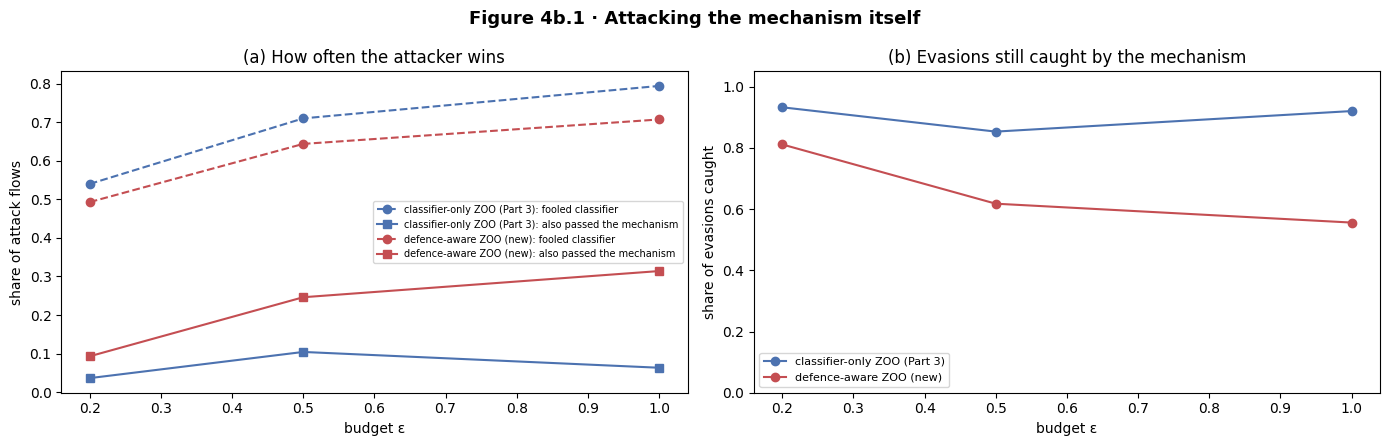

> #### Findings · defence-aware attack (ε = 1.0)
> | | classifier-only attack | defence-aware attack |
> |---|---|---|
> | attack flows that fool the classifier | 79.4% | 70.7% |
> | attack flows that fool the classifier **and** are accepted (attacker wins) | 6.3% | **31.4%** |
> | evasions caught by the mechanism | 92.0% | **55.6%** |
>
> **Meaning:** an attacker who knows the thresholds and optimises against all checks wins on 31.4% of attack flows:
> a defence-aware attacker removes much of the protection, which is an important limitation to report: the mechanism raises the attacker's cost but is not a guarantee.


In [94]:
# 4b.2 · Defence-aware adaptive attack
def margin_score(X):
    """Attacker's objective against the whole mechanism: the smallest margin over the conditions for being
    ACCEPTED as Benign (classified Benign, confident enough, not anomalous, typical explanation). >= 0 means success."""
    s = indicators(X); P = s["P"]; pb = P[:, B_ID]; other = np.delete(P, B_ID, axis=1).max(1)
    m = [pb - other]                                                         # classified Benign
    if np.isfinite(THR["tau_conf"]): m.append(pb - THR["tau_conf"])           # confident enough
    if THR["alpha"] > 0: m.append(np.clip((np.log10(np.maximum(s["p"], 1e-6)) - np.log10(THR["alpha"])) / abs(np.log10(THR["alpha"])), -1, 1))
    if np.isfinite(THR["tau_stab"]): m.append(np.clip((s["stab"] - THR["tau_stab"]) / max(1 - THR["tau_stab"], 1e-6), -1, 1))
    return np.minimum.reduce(m)
def benign_score(X): return calibrated(X)[:, B_ID]                           # Part 3 objective: fool the classifier only

def evaluate(adv_X, label):
    X = X_TL.copy(); X[pos_att] = adv_X; s = indicators(X); dec = decide(s)
    y, pred = Y_TL, s["pred"]; att = y != B_ID; acc = dec == "accept"; err = pred != y; evd = att & (pred == B_ID)
    return {"attack": label, "evaded classifier": evd[att].mean(), "evaded AND accepted (attacker wins)": (evd & acc)[att].mean(),
            "evasions caught by mechanism": 1 - (evd & acc).sum() / max(evd.sum(), 1), "errors caught": (~acc[err]).mean() if err.any() else np.nan,
            "macro-F1 (detector alone)": macro_f1(y, pred), "macro-F1 (accepted flows)": macro_f1(y[acc], pred[acc]), "accepted share": acc.mean()}

DA_RES, ADV_CACHE = [], {}
for eps in DA_EPS:
    for kind, fn in [("classifier-only ZOO (Part 3)", benign_score), ("defence-aware ZOO (new)", margin_score)]:
        t = time.time(); r = np.random.default_rng(SEED + int(eps * 1000))
        adv = realise(BASE, zoo(BASE, SCALE, eps, r, fn), SCALE); Xa = model_input(adv); ADV_CACHE[(kind, eps)] = Xa
        DA_RES.append({"eps": eps, **evaluate(Xa, kind), "seconds": round(time.time() - t)})
        print(f"  ε={eps} {kind}: {time.time() - t:.0f} s")
DA_RES = pd.DataFrame(DA_RES); DA_RES.to_csv(OUT / "stress_defence_aware.csv", index=False)
display(DA_RES.set_index(["eps", "attack"]).drop(columns="seconds").style.format("{:.3f}").set_caption("Table 4b.1 · Classifier-only vs defence-aware attack (test-lite)"))

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for kind, c in [("classifier-only ZOO (Part 3)", "#4C72B0"), ("defence-aware ZOO (new)", "#C44E52")]:
    d = DA_RES[DA_RES.attack == kind]
    axes[0].plot(d.eps, d["evaded classifier"], "--o", c=c, label=f"{kind}: fooled classifier")
    axes[0].plot(d.eps, d["evaded AND accepted (attacker wins)"], "-s", c=c, label=f"{kind}: also passed the mechanism")
    axes[1].plot(d.eps, d["evasions caught by mechanism"], "-o", c=c, label=kind)
axes[0].set(xlabel="budget ε", ylabel="share of attack flows", title="(a) How often the attacker wins"); axes[0].legend(fontsize=7)
axes[1].set(xlabel="budget ε", ylabel="share of evasions caught", title="(b) Evasions still caught by the mechanism", ylim=(0, 1.05)); axes[1].legend(fontsize=8)
plt.suptitle("Figure 4b.1 · Attacking the mechanism itself", fontsize=13, fontweight="bold"); plt.tight_layout()
plt.savefig(FIG / "4b1_defence_aware.png", dpi=200, bbox_inches="tight"); plt.show()
emax = max(DA_EPS); a_ = DA_RES[(DA_RES.eps == emax) & DA_RES.attack.str.startswith("classifier")].iloc[0]; b_ = DA_RES[(DA_RES.eps == emax) & DA_RES.attack.str.startswith("defence")].iloc[0]
display(Markdown(f"""> #### Findings · defence-aware attack (ε = {emax})
> | | classifier-only attack | defence-aware attack |
> |---|---|---|
> | attack flows that fool the classifier | {a_['evaded classifier']:.1%} | {b_['evaded classifier']:.1%} |
> | attack flows that fool the classifier **and** are accepted (attacker wins) | {a_['evaded AND accepted (attacker wins)']:.1%} | **{b_['evaded AND accepted (attacker wins)']:.1%}** |
> | evasions caught by the mechanism | {a_['evasions caught by mechanism']:.1%} | **{b_['evasions caught by mechanism']:.1%}** |
>
> **Meaning:** an attacker who knows the thresholds and optimises against all checks {"still wins on only " + format(b_['evaded AND accepted (attacker wins)'], '.1%') + " of attack flows" if b_['evaded AND accepted (attacker wins)'] < 0.25 else "wins on " + format(b_['evaded AND accepted (attacker wins)'], '.1%') + " of attack flows"}:
> {"evading the classifier, the anomaly detector and the explanation check at the same time inside the threat model is hard, so the mechanism keeps most of its protection." if b_['evasions caught by mechanism'] >= 0.6 else "a defence-aware attacker removes much of the protection, which is an important limitation to report: the mechanism raises the attacker's cost but is not a guarantee."}
"""))

## 4b.3 · Adversarial-training baseline
The standard defence: retrain the policy detector on clean training flows **plus** the adversarial versions of the `thr-lite` attack flows from Part 3 (no test flow is used), then attack it again with ZOO. This compares the mechanism with the most common alternative.

In [95]:
# 4b.3 · Adversarial-training baseline (the standard defence)
mr = pd.read_parquet(NB1 / "cicids2017_model_ready.parquet", columns=COLS + ["label_id", "split", "in_train_sample"])
X_tr = mr.loc[mr["in_train_sample"], COLS].to_numpy("float32"); y_tr = mr.loc[mr["in_train_sample"], "label_id"].to_numpy().astype(int)
test_idx = np.flatnonzero((mr["split"].astype(str) == "test").to_numpy())
X_test, y_test = mr.iloc[test_idx][COLS].to_numpy("float32"), mr.iloc[test_idx]["label_id"].to_numpy().astype(int)
Y_ALL = mr["label_id"].to_numpy().astype(int); del mr; gc.collect()
ADVF = pd.read_parquet(NB3 / "adversarial_flows.parquet")
thr_adv = ADVF[ADVF["set"].astype(str) == "thr_lite"]; tl_adv = ADVF[ADVF["set"].astype(str) == "test_lite"]
X_aug = pl.apply_preprocessing(thr_adv, PARAMS)[COLS].to_numpy("float32"); y_aug = Y_ALL[thr_adv["row_id"].to_numpy()]
P = CFG["best_params"][POLICY]
def fit_xgb(X, y, seed):
    return xgb.XGBClassifier(objective="multi:softprob", num_class=K, tree_method="hist", device=DEVICE, n_estimators=P["n_estimators"],
                             max_depth=P["max_depth"], learning_rate=P["learning_rate"], subsample=P["subsample"], colsample_bytree=P["colsample_bytree"],
                             min_child_weight=P["min_child_weight"], reg_lambda=P["reg_lambda"], random_state=seed, n_jobs=-1,
                             eval_metric="mlogloss").fit(X, y, sample_weight=CW_VEC[y], verbose=False)
t = time.time(); AT_MODEL = fit_xgb(np.vstack([X_tr, X_aug]), np.concatenate([y_tr, y_aug]), SEED)
print(f"adversarially trained {POLICY}: {len(X_tr):,} clean + {len(X_aug):,} adversarial training flows ({time.time() - t:.0f} s)")

X_TLADV = pl.apply_preprocessing(tl_adv, PARAMS)[COLS].to_numpy("float32"); Y_TLADV = Y_ALL[tl_adv["row_id"].to_numpy()]
TL_GROUPS = tl_adv.groupby(["attack", "target", "eps"]).indices
def transfer_f1(model):                 # Part 3's adversarial test-lite flows, averaged over all attack configurations
    X, yb, groups = X_TLADV, Y_TLADV, TL_GROUPS; ben = Y_TL == B_ID; f = []
    p_ben = model.predict_proba(X_TL[ben]).argmax(1)
    for _, ix in groups.items():
        y = np.concatenate([Y_TL[ben], yb[ix]]); p = np.concatenate([p_ben, model.predict_proba(X[ix]).argmax(1)]); f.append(macro_f1(y, p))
    return float(np.mean(f))
def adaptive_f1(model):                 # classifier-only ZOO against THIS model at the largest budget
    r = np.random.default_rng(SEED + int(emax * 1000))
    d = zoo(BASE, SCALE, emax, r, lambda X: model.predict_proba(X)[:, B_ID]); Xa = model_input(realise(BASE, d, SCALE))
    X = X_TL.copy(); X[pos_att] = Xa; return macro_f1(Y_TL, model.predict_proba(X).argmax(1))

mech = DA_RES[(DA_RES.eps == emax)].set_index("attack")
AT_TAB = pd.DataFrame([
    {"system": f"{POLICY.upper()} (Part 2)", "clean test macro-F1": macro_f1(y_test, MODEL.predict_proba(X_test).argmax(1)),
     "transferred attacks (Part 3)": transfer_f1(MODEL), f"adaptive ZOO ε={emax}": mech.loc["classifier-only ZOO (Part 3)", "macro-F1 (detector alone)"]},
    {"system": f"{POLICY.upper()} + adversarial training", "clean test macro-F1": macro_f1(y_test, AT_MODEL.predict_proba(X_test).argmax(1)),
     "transferred attacks (Part 3)": transfer_f1(AT_MODEL), f"adaptive ZOO ε={emax}": adaptive_f1(AT_MODEL)},
    {"system": f"{POLICY.upper()} + confidence-aware mechanism (accepted flows)", "clean test macro-F1": np.nan, "transferred attacks (Part 3)": np.nan,
     f"adaptive ZOO ε={emax}": mech.loc["classifier-only ZOO (Part 3)", "macro-F1 (accepted flows)"]},
    {"system": "… under the defence-aware attack (accepted flows)", "clean test macro-F1": np.nan, "transferred attacks (Part 3)": np.nan,
     f"adaptive ZOO ε={emax}": mech.loc["defence-aware ZOO (new)", "macro-F1 (accepted flows)"]}]).set_index("system")
AT_TAB.to_csv(OUT / "stress_adversarial_training.csv")
display(AT_TAB.style.format("{:.3f}", na_rep="—").set_caption("Table 4b.2 · Adversarial training vs the confidence-aware mechanism (macro-F1)"))
at_gain = AT_TAB.iloc[1, 2] - AT_TAB.iloc[0, 2]
display(Markdown(f"""> #### Findings · adversarial training
> Retraining on {len(X_aug):,} adversarial flows changes clean macro-F1 by {AT_TAB.iloc[1, 0] - AT_TAB.iloc[0, 0]:+.3f} and macro-F1 under the adaptive attack by **{at_gain:+.3f}**
> ({AT_TAB.iloc[0, 2]:.3f} → {AT_TAB.iloc[1, 2]:.3f}). The mechanism instead keeps the accepted flows at {AT_TAB.iloc[2, 2]:.3f} ({AT_TAB.iloc[3, 2]:.3f} under the defence-aware attack).
>
> **Meaning:** {"adversarial training alone does not restore robustness against an adaptive attacker, while the mechanism protects the decisions it accepts; the two are complementary (the mechanism can wrap an adversarially trained model)." if AT_TAB.iloc[1, 2] < AT_TAB.iloc[2, 2] else "adversarial training is stronger on this attack. This is its most favourable setting: it was trained on adversarial flows from the same "
    "attack generator it is tested against, whereas the mechanism needs no attack examples (and flags most never-seen attack families, Section 4.11). "
    "Wrapping the mechanism around an adversarially trained detector is the natural next step."}
"""))

adversarially trained xgb: 321,277 clean + 36,000 adversarial training flows (21 s)


,clean test macro-F1,transferred attacks (Part 3),adaptive ZOO ε=1.0
system,,,
XGB (Part 2),0.940,0.728,0.253
XGB + adversarial training,0.938,0.998,0.960
XGB + confidence-aware mechanism (accepted flows),—,—,0.465
… under the defence-aware attack (accepted flows),—,—,0.452


> #### Findings · adversarial training
> Retraining on 36,000 adversarial flows changes clean macro-F1 by -0.003 and macro-F1 under the adaptive attack by **+0.707**
> (0.253 → 0.960). The mechanism instead keeps the accepted flows at 0.465 (0.452 under the defence-aware attack).
>
> **Meaning:** adversarial training is stronger on this attack. This is its most favourable setting: it was trained on adversarial flows from the same attack generator it is tested against, whereas the mechanism needs no attack examples (and flags most never-seen attack families, Section 4.11). Wrapping the mechanism around an adversarially trained detector is the natural next step.


## 4b.4 · Seed robustness
XGBoost and Random Forest are retrained with three further random seeds and evaluated on the clean test set and on Part 3's attacked flows.

*Note on the numbers.* This test compares raw model outputs (argmax of the uncalibrated probabilities) across seeds, so its clean macro-F1 differs from Part 2, which reports the argmax of the **calibrated** probabilities on the same test set (XGBoost 0.941 raw vs 0.956 calibrated; RF 0.953 raw vs 0.946 calibrated; the reported seed-42 model is included in both). Calibration changes the predicted class of a few borderline flows, mostly in the small Bot class. Only the spread across seeds matters here, and it is below 0.001 for clean data.

In [96]:
# 4b.4 · Seed robustness: retrain the tree models with other seeds
B_RF = CFG["best_params"]["rf"]; SEED_TAB = []
for seed in [SEED] + SEEDS:
    for name in ["xgb", "rf"]:
        t = time.time()
        if seed == SEED and name == POLICY: m = MODEL
        elif name == "xgb": m = fit_xgb(X_tr, y_tr, seed)
        else:
            if seed == SEED: m = joblib.load(MD / "rf.joblib")
            else:
                m = RandomForestClassifier(n_estimators=200, max_depth=B_RF["max_depth"], min_samples_leaf=B_RF["min_samples_leaf"],
                                           max_features=B_RF["max_features"], n_jobs=-1, random_state=seed).fit(X_tr, y_tr, sample_weight=CW_VEC[y_tr])
        SEED_TAB.append({"model": name, "seed": seed, "clean test macro-F1": macro_f1(y_test, m.predict_proba(X_test).argmax(1)),
                         "transferred attacks macro-F1": transfer_f1(m)})
        print(f"  {name} seed {seed}: {time.time() - t:.0f} s"); 
        if m is not MODEL: del m; gc.collect()
SEED_TAB = pd.DataFrame(SEED_TAB); SEED_TAB.to_csv(OUT / "stress_seeds.csv", index=False)
SUMM = SEED_TAB.groupby("model")[["clean test macro-F1", "transferred attacks macro-F1"]].agg(["mean", "std", "min", "max"])
display(SUMM.style.format("{:.4f}").set_caption(f"Table 4b.3 · Variation over {len(SEEDS) + 1} training seeds"))
display(Markdown("> #### Findings · seeds\n> " + " · ".join(
    f"**{m}**: clean {SUMM.loc[m, ('clean test macro-F1', 'mean')]:.4f} ± {SUMM.loc[m, ('clean test macro-F1', 'std')]:.4f}, "
    f"under attack {SUMM.loc[m, ('transferred attacks macro-F1', 'mean')]:.3f} ± {SUMM.loc[m, ('transferred attacks macro-F1', 'std')]:.3f}" for m in SUMM.index)
    + ("\n>\n> **Meaning:** the spread across seeds (largest standard deviation " + f"{SUMM.xs('std', axis=1, level=1).max().max():.4f}"
       + (") is far smaller than the differences reported in Parts 3–5, so the conclusions do not depend on one random seed."
          if SUMM.xs('std', axis=1, level=1).max().max() < 0.02 else
          ") is not negligible; differences smaller than this should not be interpreted."))))

  xgb seed 42: 1 s
  rf seed 42: 5 s
  xgb seed 1: 20 s
  rf seed 1: 130 s
  xgb seed 2: 20 s
  rf seed 2: 132 s
  xgb seed 3: 20 s
  rf seed 3: 132 s


> #### Findings · seeds
> **rf**: clean 0.9530 ± 0.0004, under attack 0.594 ± 0.013 · **xgb**: clean 0.9408 ± 0.0005, under attack 0.737 ± 0.007
>
> **Meaning:** the spread across seeds (largest standard deviation 0.0126) is far smaller than the differences reported in Parts 3–5, so the conclusions do not depend on one random seed.

## 4b.5 · Analyst-workload sweep
The rule of Part 4 is re-tuned on `thr-lite` for false-flag budgets from 1 % to 20 % and evaluated on `test-lite`, giving the trade-off between protection and analyst workload.

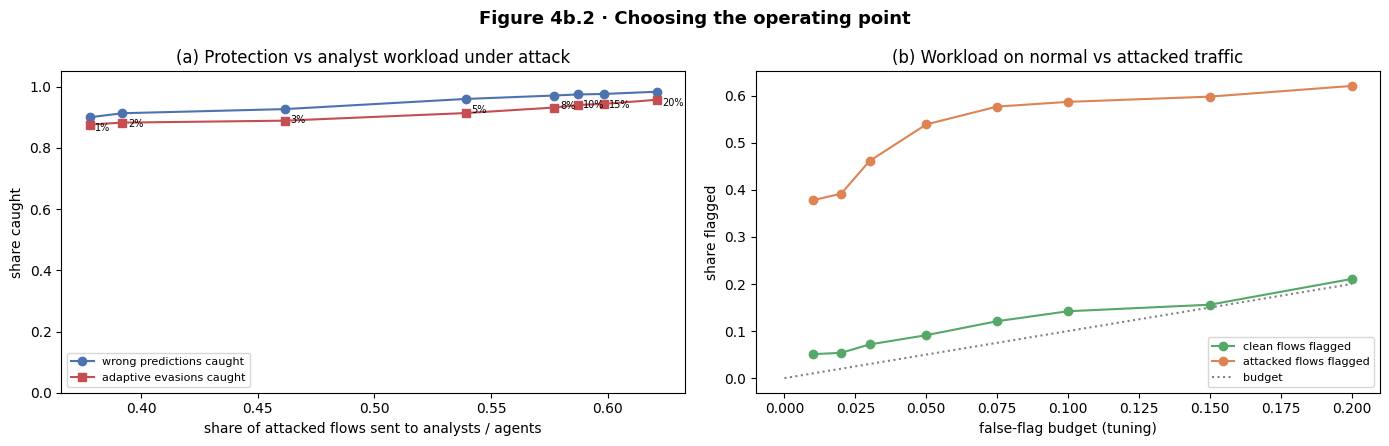

budget,clean flows flagged,attacked flows flagged,errors caught (attacked),evasions caught (adaptive ZOO)
1.0%,0.051,0.378,0.900,0.876
2.0%,0.054,0.392,0.913,0.882
3.0%,0.072,0.461,0.927,0.889
5.0%,0.091,0.539,0.960,0.914
7.5%,0.121,0.577,0.971,0.932
10.0%,0.142,0.587,0.974,0.940
15.0%,0.156,0.598,0.976,0.944
20.0%,0.211,0.621,0.983,0.957


> #### Findings · workload
> At a **1%** false-flag budget the mechanism catches 90.0% of wrong predictions under attack while sending 37.8% of attacked flows onward; at 20% it catches 98.3% with 62.1% sent onward.
> Operators can choose the operating point along Figure 4b.2: a tighter budget lowers analyst workload at the cost of more missed errors.

In [97]:
# 4b.5 · Analyst-workload sweep: re-tune the rule of Part 4 at several false-flag budgets
FT = pd.read_parquet(NB4 / "policy_flags_thr.parquet"); FE = pd.read_parquet(NB4 / "policy_flags_test.parquet")
FE = FE[FE["set"] == "test"]; T = FT[FT["group"] != "zoo_direct"]
c_T, pr_T, p_T, s_T = (T[c].to_numpy() for c in ["conf", "pred", "anomaly_p", "stability"])
err_T = T["is_error"].to_numpy(); cc_T = ((T["variant"] == "clean") & ~T["is_error"]).to_numpy()
CONF_GRID = np.unique(np.r_[-np.inf, np.quantile(c_T, np.linspace(0, 0.30, 16)[1:])]); STAB_GRID = np.unique(np.r_[-np.inf, np.quantile(s_T, np.linspace(0, 0.30, 16)[1:])])
ALPHA_GRID, BETA_GRID = [0.0, 0.001, 0.005, 0.01, 0.02, 0.05], [0.50, 0.80, 0.95, 1.01]
def tune(budget):
    LC = c_T[None, :] < CONF_GRID[:, None]; US = s_T[None, :] < STAB_GRID[:, None]; best, key_b = None, None
    for a in ALPHA_GRID:
        EV = (pr_T == B_ID) & (p_T < a)
        for b in BETA_GRID:
            base = EV | ((pr_T != B_ID) & (p_T > b))
            for i, tc in enumerate(CONF_GRID):
                fl = (LC[i] | base)[None, :] | US; ff = fl[:, cc_T].mean(1); ca = fl[:, err_T].mean(1); fr = fl.mean(1)
                for j in np.flatnonzero(ff <= budget + 1e-12):
                    k = (round(float(ca[j]), 6), -float(fr[j]))
                    if key_b is None or k > key_b: key_b, best = k, (tc, a, b, STAB_GRID[j])
    return best
SW = []
for bud in BUDGETS:
    tc, a, b, ts = tune(bud)
    pred, pv = FE["pred"].to_numpy(), FE["anomaly_p"].to_numpy()
    flag = (FE["conf"].to_numpy() < tc) | ((pred == B_ID) & (pv < a)) | ((pred != B_ID) & (pv > b)) | (FE["stability"].to_numpy() < ts)
    cl, at = (FE["variant"] == "clean").to_numpy(), (FE["variant"] == "attacked").to_numpy(); er, ev = FE["is_error"].to_numpy(), FE["is_evasion"].to_numpy()
    zd = (FE["group"] == "zoo_direct").to_numpy()
    SW.append({"budget": bud, "clean flows flagged": flag[cl].mean(), "attacked flows flagged": flag[at].mean(),
               "errors caught (attacked)": flag[at & er].mean(), "evasions caught (adaptive ZOO)": flag[zd & ev].mean()})
SW = pd.DataFrame(SW); SW.to_csv(OUT / "stress_workload_sweep.csv", index=False)
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
ax[0].plot(SW["attacked flows flagged"], SW["errors caught (attacked)"], "-o", c="#4C72B0", label="wrong predictions caught")
ax[0].plot(SW["attacked flows flagged"], SW["evasions caught (adaptive ZOO)"], "-s", c="#C44E52", label="adaptive evasions caught")
for _, r in SW.iterrows(): ax[0].annotate(f"{r.budget:.0%}", (r["attacked flows flagged"], r["errors caught (attacked)"]), xytext=(4, -10), textcoords="offset points", fontsize=7)
ax[0].set(xlabel="share of attacked flows sent to analysts / agents", ylabel="share caught", title="(a) Protection vs analyst workload under attack", ylim=(0, 1.05)); ax[0].legend(fontsize=8)
ax[1].plot(SW["budget"], SW["clean flows flagged"], "-o", c="#55A868", label="clean flows flagged"); ax[1].plot(SW["budget"], SW["attacked flows flagged"], "-o", c="#DD8452", label="attacked flows flagged")
ax[1].plot([0, max(BUDGETS)], [0, max(BUDGETS)], ":", c="grey", label="budget"); ax[1].set(xlabel="false-flag budget (tuning)", ylabel="share flagged", title="(b) Workload on normal vs attacked traffic"); ax[1].legend(fontsize=8)
plt.suptitle("Figure 4b.2 · Choosing the operating point", fontsize=13, fontweight="bold"); plt.tight_layout(); plt.savefig(FIG / "4b2_workload.png", dpi=200, bbox_inches="tight"); plt.show()
display(SW.style.format({"budget": "{:.1%}", **{c: "{:.3f}" for c in SW.columns if c != "budget"}}).hide(axis="index").set_caption("Table 4b.4 · Workload sweep (thresholds re-tuned on thr-lite, evaluated on test-lite)"))
lo_ = SW.iloc[0]
display(Markdown(f"""> #### Findings · workload
> At a **{lo_.budget:.0%}** false-flag budget the mechanism catches {lo_['errors caught (attacked)']:.1%} of wrong predictions under attack while sending {lo_['attacked flows flagged']:.1%} of attacked flows onward; at {SW.iloc[-1].budget:.0%} it catches {SW.iloc[-1]['errors caught (attacked)']:.1%} with {SW.iloc[-1]['attacked flows flagged']:.1%} sent onward.
> Operators can choose the operating point along Figure 4b.2: a tighter budget lowers analyst workload at the cost of more missed errors."""))

> #### ✅ Part 4b · Key takeaways
> The Findings boxes above report, from this run: how much protection survives an attacker who knows the mechanism (4b.2), how the mechanism compares with adversarial training (4b.3), how much results vary with the training seed (4b.4), and how protection trades off against analyst workload (4b.5). Part 6.9 summarises them next to the research questions.

↑ back to contents (Notebook 1)

---
## Viva guide for this notebook

**Suggested demonstration path (about 6 minutes)**
1. **Figure 4.1**: the mechanism (three indicators, four checks, three outcomes).
2. **4.5b**: why prototype similarity was chosen (AUROC 0.867 vs 0.794).
3. **4.7–4.8**: evaluation and the ablation table (confidence alone 41.4 % → full rule 96.0 %).
4. **4.10**: bootstrap differences (established).
5. **4.11**: never-seen families.
6. **4b.2–4b.3**: the honest limits (defence-aware attacker; adversarial training).

**Likely questions and short answers**

| Question | Answer |
|---|---|
| What is new in your mechanism? | It fuses three independent trust indicators, including a deployable explanation-robustness indicator, into a transparent accept / flag / escalate rule, tested against an attack never used for tuning. |
| Why is confidence alone not enough? | An adversarial flow is by design a confident mistake: confidence alone caught only 41.4 % of errors under attack. |
| What does most of the work? | Classifier–anomaly disagreement: an attacker who pushes a flow into Benign must also make it look benign to a model of normal traffic. |
| Does the explanation indicator add anything? | Alone it beats confidence (AUROC 0.867 vs 0.738); inside the full rule it adds +0.6 points of errors caught (established) and 1.5 points of accepted macro-F1; the learned combiner weights it more than confidence. |
| How did you avoid tuning on the test attack? | Thresholds were tuned on thr-lite with the ZOO flows crafted against the policy detector excluded. |
| What is the cost? | About 8.7 ms per flow, but analyst workload rises under attack: only 46.1 % of attacked flows are accepted automatically. |
| Can an attacker beat it? | Partly: a defence-aware attacker reduced evasions caught from 92 % to 56 %. It raises the attacker's cost but is not a guarantee. |
| Why not just use adversarial training? | It is stronger on the attack it was trained on (0.960), but needs attack examples; the mechanism needs none and escalates most never-seen attacks. They can be combined. |